# Netflix Content Intelligence — Exploratory Analysis and Clustering

## Project scope
This notebook follows an end-to-end unsupervised machine-learning workflow for Netflix titles:
1. Load and inspect the dataset
2. Clean data and perform exploratory data analysis (EDA)
3. Test selected statistical hypotheses
4. Engineer genre and description features
5. Reduce dimensionality for selected clustering algorithms
6. Train and evaluate clustering models
7. Interpret clusters and compare model behaviour

## Analytical principles
- Use the full dataset for descriptive calculations unless a step explicitly uses a sample for computational reasons.
- Use a reproducible sample for expensive metric calculations and DBSCAN parameter exploration.
- Genre labels are multi-label: one title may contribute to several category counts.
- Cluster labels are arbitrary identifiers, not rankings.
- Association and cluster patterns do not establish causation.
- Clustering metrics are only comparable when their feature representation, distance metric, and evaluation sample are aligned.


## Project Summary

This project analyses the Netflix Movies and TV Shows dataset using
exploratory data analysis, statistical hypothesis testing, and
unsupervised machine learning.

Genre information and textual descriptions are transformed into
numerical features and used to cluster similar titles. Four clustering
algorithms are evaluated using internal metrics and cluster-content
interpretation to identify a suitable approach for organising the
Netflix catalogue.

## GitHub Link

Repository: https://github.com/Brian-Fernandes/Netflix_EDA

## Problem Statement

The Netflix catalogue contains movies and TV shows with different genres, release years, ratings, countries, and textual descriptions. Analysing this information can help reveal patterns in the catalogue and similarities between titles.

The objective of this project is to analyse the Netflix catalogue using Exploratory Data Analysis (EDA), statistical hypothesis testing, and unsupervised machine learning. The study aims to identify important catalogue patterns, group similar titles using their genres and descriptions, and compare clustering algorithms to determine which produces the most interpretable groups.

The project focuses on content analysis and clustering rather than personalised recommendations or individual user behaviour prediction, as the available dataset does not contain user-level interaction data.

## Research Questions and Objectives

### Research Questions

1. What are the major characteristics and patterns in the Netflix catalogue?
2. Do movies and TV shows differ in their release-year distributions?
3. Is there a statistically significant association between content type and rating?
4. Can Netflix titles be grouped into meaningful clusters using genres and descriptions?
5. Which clustering algorithm provides the most useful balance of cluster quality and interpretability?

### Objectives

- Perform data cleaning and exploratory data analysis.
- Examine catalogue characteristics using statistical summaries and visualisations.
- Apply appropriate statistical tests to investigate selected relationships.
- Transform genre and description data into numerical features.
- Apply and compare multiple clustering algorithms.
- Interpret cluster contents and identify the most suitable model for this experiment.

## Contents
1. [Problem Statement](#problem-statement)
2. [Research Questions and Objectives](#research-questions-and-objectives)
3. [Import Libraries](#1.-import-libraries)
4. [Load Dataset](#2.-load-dataset)
5. [Initial Dataset Inspection](#3.-initial-dataset-inspection)
6. [Data Cleaning](#4.-data-cleaning)
7. [Univariate EDA](#5.-univariate-exploratory-data-analysis)
8. [Bivariate EDA](#6.-bivariate-exploratory-data-analysis)
9. [Statistical Hypothesis Testing](#7.-statistical-hypothesis-testing)
10. [Multivariate EDA](#8.-multivariate-exploratory-analysis)
11. [Key Findings from EDA](#key-findings-from-exploratory-data-analysis)
12. [Feature Engineering](#9.-feature-engineering-and-representation)
13. [Machine Learning Approach](#machine-learning-approach)
14. [Evaluation Sample](#10.-prepare-a-reproducible-evaluation-sample)
15. [Clustering Models and Comparison](#16.-final-model-comparison-and-conclusion)
16. [Key Findings from Clustering](#key-findings-from-clustering)
17. [Final Conclusion](#final-conclusion)
1. [Import Libraries](#1.-Import-Libraries)
2. [Load Dataset](#2.-Load-Dataset)
3. [Initial Dataset Inspection](#3.-Initial-Dataset-Inspection)
4. [Data Cleaning](#4.-Data-Cleaning)
5. [Univariate EDA](#5.-Univariate-Exploratory-Data-Analysis)
6. [Bivariate EDA](#6.-Bivariate-Exploratory-Data-Analysis)
7. [Statistical Hypothesis Testing](#7.-Statistical-Hypothesis-Testing)
8. [Multivariate EDA](#8.-Multivariate-Exploratory-Analysis)
9. [Feature Engineering](#9.-Feature-Engineering-and-Representation)
10. [Evaluation Sample](#10.-Prepare-a-Reproducible-Evaluation-Sample)
11. [MiniBatch K-Means](#11.-Model-1-—-MiniBatch-K-Means)
12. [Bisecting K-Means](#12.-Model-2-—-Bisecting-K-Means)
13. [Truncated SVD](#13.-Dimensionality-Reduction-with-Truncated-SVD)
14. [Agglomerative Clustering](#14.-Model-3-—-Agglomerative-Clustering)
15. [DBSCAN](#15.-Model-4-—-DBSCAN-Parameter-Search-and-Interpretation)
16. [Final Model Comparison and Conclusion](#16.-Final-Model-Comparison-and-Conclusion)


## 1. Import Libraries

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 140)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load Dataset

In [2]:
# Expected dataset name from the project
candidate_files = [
    "NETFLIX MOVIES AND TV SHOWS CLUSTERING.csv",
    "netflix_titles.csv"
]

file_path = next((f for f in candidate_files if os.path.exists(f)), None)

if file_path is None:
    raise FileNotFoundError(
        "Dataset CSV not found. Upload 'NETFLIX MOVIES AND TV SHOWS CLUSTERING.csv' "
        "to the Colab working directory and run this cell again."
    )

df = pd.read_csv(file_path)

print(f"Dataset loaded successfully: {file_path}")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully: NETFLIX MOVIES AND TV SHOWS CLUSTERING.csv
Dataset shape: (7787, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, Rodolfo Valente, Vaneza Oliveira, Rafael Lozano, Viviane Porto, Mel Fro...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi & Fantasy","In a future where the elite inhabit an island paradise far from the crowded slums, you get one chance to join the 3%..."
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, Azalia Ortiz, Octavio Michel, Carmen Beato",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies","After a devastating earthquake hits Mexico City, trapped survivors from all walks of life wait to be rescued while t..."
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence Koh, Tommy Kuan, Josh Lai, Mark Lee, Susan Leong, Benjamin Lim",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow soldiers are forced to confront a terrifying secret that's haunting t..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly, Christopher Plummer, Crispin Glover, Martin Landau, Fred Tatasciore,...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi & Fantasy","In a postapocalyptic world, rag-doll robots hide in fear from dangerous machines out to exterminate them, until a br..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aaron Yoo, Liza Lapira, Jacob Pitts, Laurence Fishburne, Jack McGee, Josh...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-counting experts with the intent of swindling millions out of Las Vegas ca...


## 3. Initial Dataset Inspection

In [3]:
print("Column names:")
display(pd.DataFrame({"Column": df.columns}))

print("\nData types and non-null counts:")
df.info()

Column names:


,Column
0,show_id
1,type
2,title
3,director
4,cast
5,country
6,date_added
7,release_year
8,rating
9,duration



Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7787 non-null   object
 1   type          7787 non-null   object
 2   title         7787 non-null   object
 3   director      5398 non-null   object
 4   cast          7069 non-null   object
 5   country       7280 non-null   object
 6   date_added    7777 non-null   object
 7   release_year  7787 non-null   int64 
 8   rating        7780 non-null   object
 9   duration      7787 non-null   object
 10  listed_in     7787 non-null   object
 11  description   7787 non-null   object
dtypes: int64(1), object(11)
memory usage: 730.2+ KB


In [4]:
print("Descriptive statistics:")
display(df.describe(include="all").T)

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,7787,7787,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,7787,2,Movie,5377,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,7787,7787,3%,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,5398,4049,"Raúl Campos, Jan Suter",18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7069,6831,David Attenborough,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7280,681,United States,2555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,7777,1565,"January 1, 2020",118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,7787.0,NaN,NaN,NaN,2013.93258,8.757395,1925.0,2013.0,2017.0,2018.0,2021.0
rating,7780,14,TV-MA,2863,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,7787,216,1 Season,1608,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values:")
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Count", ascending=False)

display(missing_summary)

Duplicate rows: 0

Missing values:


,Missing Count,Missing Percentage
director,2389,30.68
cast,718,9.22
country,507,6.51
date_added,10,0.13
rating,7,0.09
title,0,0.00
show_id,0,0.00
type,0,0.00
release_year,0,0.00
duration,0,0.00


## 4. Data Cleaning

The dataset contains missing values mainly in `director`, `cast`, `country`, `date_added`, and `rating`.

For this project:
- `director`, `cast`, `country`, and `date_added` missing values are represented as `"Unknown"`.
- Missing `rating` values are replaced with the mode because rating is categorical.
- `date_added` is intentionally retained as text; no unnecessary date conversion is performed at this stage.


In [6]:

# Handle missing values

df["director"] = df["director"].fillna("Unknown")
df["cast"] = df["cast"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")
df["date_added"] = df["date_added"].fillna("Unknown")

# Preserve missing ratings instead of assigning the most frequent rating
df["rating"] = df["rating"].fillna("Unknown")

print("Missing values after cleaning:")
display(df.isna().sum().to_frame("Missing Count"))


Missing values after cleaning:


,Missing Count
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0


In [7]:
# Verify duplicates after cleaning
print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Final dataset shape:", df.shape)

Duplicate rows after cleaning: 0
Final dataset shape: (7787, 12)


# 5. Univariate Exploratory Data Analysis

Univariate analysis examines each important variable independently to understand the structure of the dataset before studying relationships between variables.


## 5.1 Content Type Distribution

In [8]:
type_counts = df["type"].value_counts()
type_percentage = df["type"].value_counts(normalize=True).mul(100).round(2)

type_summary = pd.DataFrame({
    "Count": type_counts,
    "Percentage": type_percentage
})

display(type_summary)

,Count,Percentage
type,,
Movie,5377,69.05
TV Show,2410,30.95


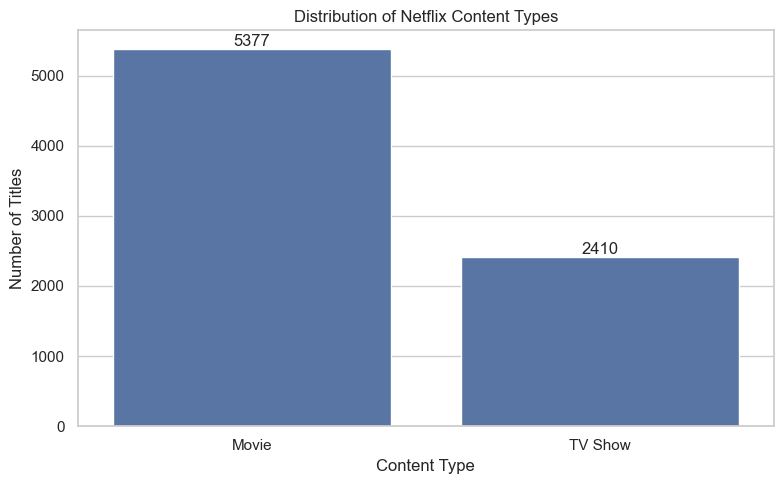

In [9]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x="type", order=type_counts.index)

plt.title("Distribution of Netflix Content Types")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

## 5.2 Release Year Distribution

In [10]:
print("Release year statistics:")
display(df["release_year"].describe().to_frame("Release Year"))

Release year statistics:


,Release Year
count,7787.000000
mean,2013.932580
std,8.757395
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2018.000000
max,2021.000000


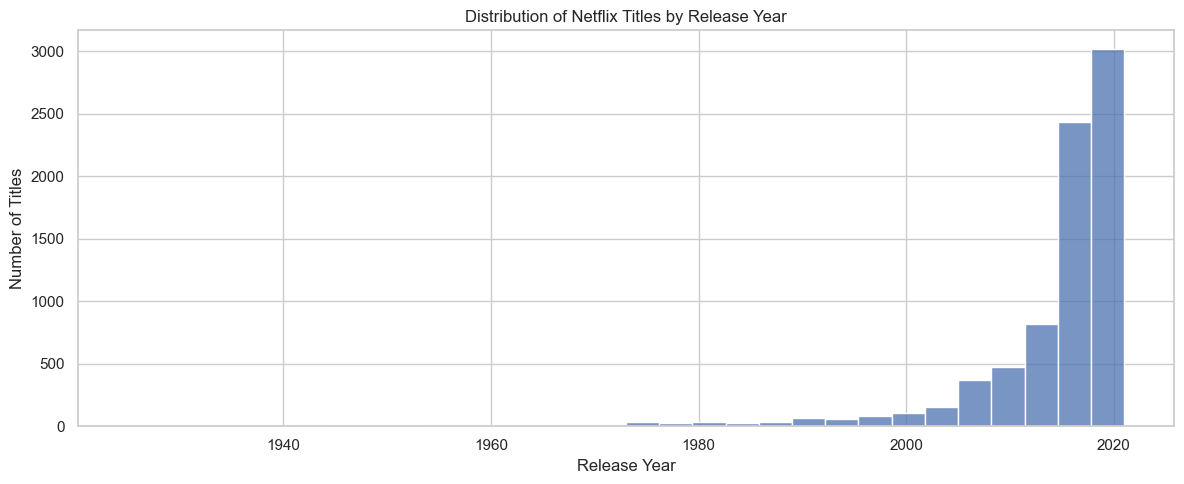

In [11]:
plt.figure(figsize=(12, 5))
sns.histplot(data=df, x="release_year", bins=30)

plt.title("Distribution of Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

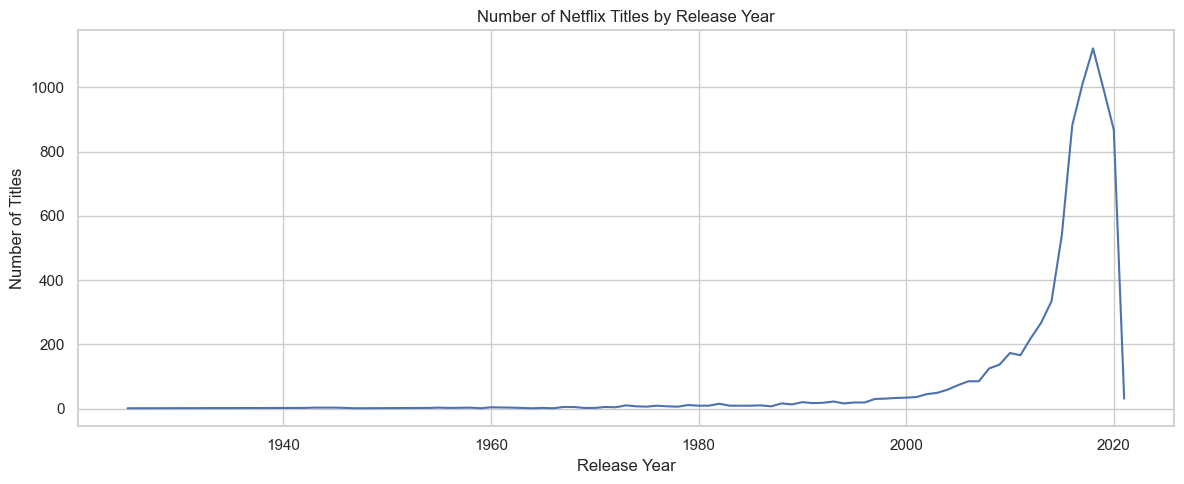

In [12]:
year_counts = df["release_year"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(year_counts.index, year_counts.values)

plt.title("Number of Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

## 5.3 Genre / Category Distribution

`listed_in` contains multiple comma-separated categories for many titles. The values are therefore split and exploded so that each category can be counted independently.

The calculation uses **all categories**. The Top-15 chart is only a readability-focused visualization.


In [13]:
genre_counts = (
    df["listed_in"]
      .str.split(", ")
      .explode()
      .value_counts()
)

print("Number of unique genres/categories:", len(genre_counts))
display(genre_counts.to_frame("Title Count"))

Number of unique genres/categories: 42


,Title Count
listed_in,
International Movies,2437
Dramas,2106
Comedies,1471
International TV Shows,1199
Documentaries,786
Action & Adventure,721
TV Dramas,704
Independent Movies,673
Children & Family Movies,532


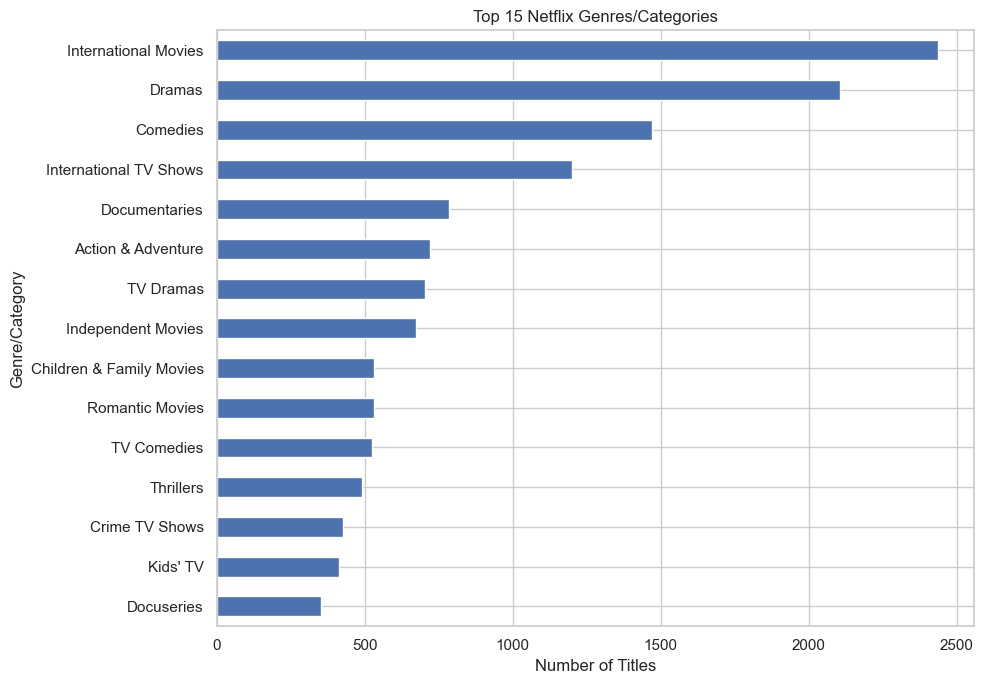

In [14]:
top_genres = genre_counts.head(15).sort_values()

plt.figure(figsize=(10, 7))
ax = top_genres.plot(kind="barh")

plt.title("Top 15 Netflix Genres/Categories")
plt.xlabel("Number of Titles")
plt.ylabel("Genre/Category")
plt.tight_layout()
plt.show()

## 5.4 Country Distribution

A title can contain multiple countries, so `country` is also split and exploded.

All countries are retained for calculation. The Top-15 visualization is used only to make the distribution readable.


In [15]:
country_counts = (
    df["country"]
      .str.split(", ")
      .explode()
      .value_counts()
)

country_counts = country_counts[country_counts.index != "Unknown"]

print("Number of countries represented:", len(country_counts))
display(country_counts.to_frame("Title Count"))

Number of countries represented: 121


,Title Count
country,
United States,3296
India,990
United Kingdom,722
Canada,412
France,349
...,...
Panama,1
"United Kingdom,",1
Uganda,1


In [ ]:
top_countries = country_counts.head(15).sort_values()

plt.figure(figsize=(10, 7))
top_countries.plot(kind="barh")

plt.title("Top 15 Countries by Number of Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## 5.5 Content Rating Distribution

In [ ]:
rating_counts = df["rating"].value_counts()

print("Number of unique ratings:", len(rating_counts))
display(rating_counts.to_frame("Title Count"))

Number of unique ratings: 15


,Title Count
rating,
TV-MA,2863
TV-14,1931
TV-PG,806
R,665
PG-13,386
TV-Y,280
TV-Y7,271
PG,247
TV-G,194


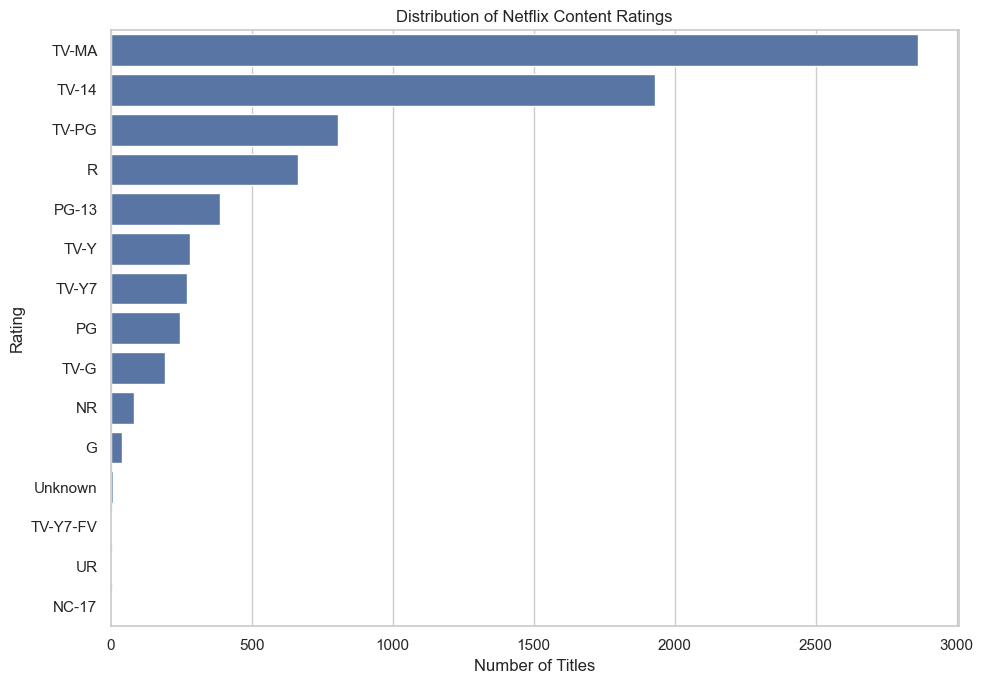

In [ ]:
plt.figure(figsize=(10, 7))
sns.countplot(
    data=df,
    y="rating",
    order=rating_counts.index
)

plt.title("Distribution of Netflix Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

# 6. Bivariate Exploratory Data Analysis

Bivariate analysis examines meaningful relationships between two variables.

The analyses below were selected because they can reveal useful structure in the Netflix catalog. Relationships that are redundant (for example, genre labels that already encode content type) or dominated by very small samples are intentionally excluded.


## 6.1 Content Type × Rating

In [ ]:
type_rating_counts = pd.crosstab(
    df["rating"],
    df["type"]
)

print("Content Type by Rating — Counts")
display(type_rating_counts)

Content Type by Rating — Counts


type,Movie,TV Show
rating,,
G,39,0
NC-17,3,0
NR,79,5
PG,247,0
PG-13,386,0
R,663,2
TV-14,1272,659
TV-G,111,83
TV-MA,1845,1018


In [ ]:
type_rating_pct = pd.crosstab(
    df["rating"],
    df["type"],
    normalize="index"
).mul(100).round(2)

print("Content Type by Rating — Row Percentages")
display(type_rating_pct)

Content Type by Rating — Row Percentages


type,Movie,TV Show
rating,,
G,100.00,0.00
NC-17,100.00,0.00
NR,94.05,5.95
PG,100.00,0.00
PG-13,100.00,0.00
R,99.70,0.30
TV-14,65.87,34.13
TV-G,57.22,42.78
TV-MA,64.44,35.56


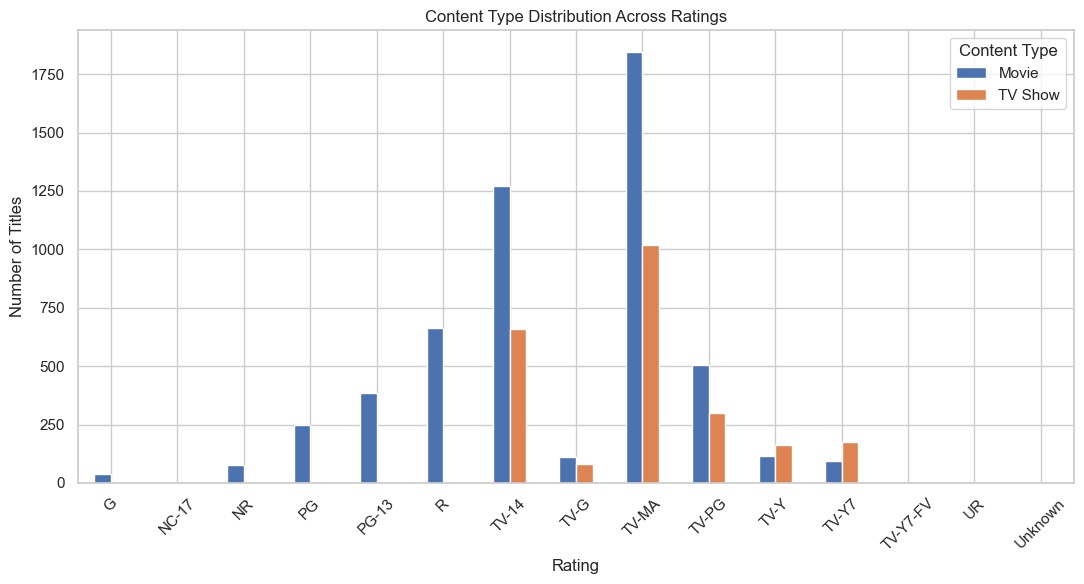

In [ ]:
type_rating_counts.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Content Type Distribution Across Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

## 6.2 Release Decade × Content Type

In [ ]:
# Group release years into decades to reduce year-by-year noise.
df["release_decade"] = (df["release_year"] // 10) * 10

decade_type_counts = pd.crosstab(
    df["release_decade"],
    df["type"]
)

display(decade_type_counts)

type,Movie,TV Show
release_decade,,
1920,0,1
1940,13,1
1950,11,0
1960,22,3
1970,63,4
1980,99,7
1990,194,31
2000,601,127
2010,3951,1760


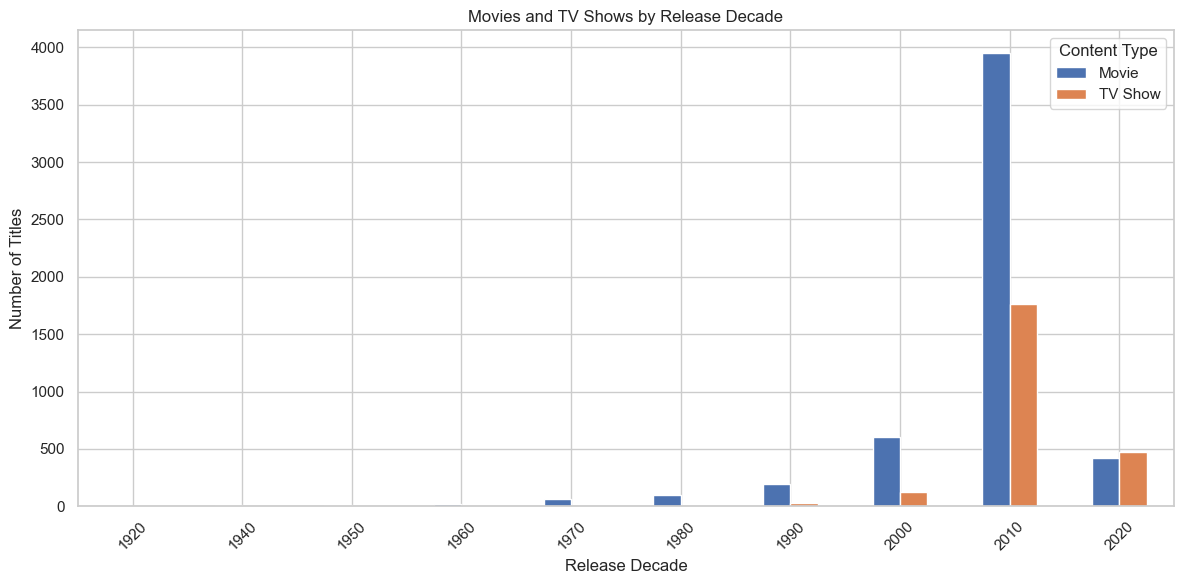

In [ ]:
decade_type_counts.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Movies and TV Shows by Release Decade")
plt.xlabel("Release Decade")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

In [ ]:
tv_share_by_decade = (
    decade_type_counts["TV Show"]
    .div(decade_type_counts.sum(axis=1))
    .mul(100)
    .round(2)
)

print("TV Show share by release decade:")
display(tv_share_by_decade.to_frame("TV Show Share (%)"))

TV Show share by release decade:


,TV Show Share (%)
release_decade,
1920,100.00
1940,7.14
1950,0.00
1960,12.00
1970,5.97
1980,6.60
1990,13.78
2000,17.45
2010,30.82


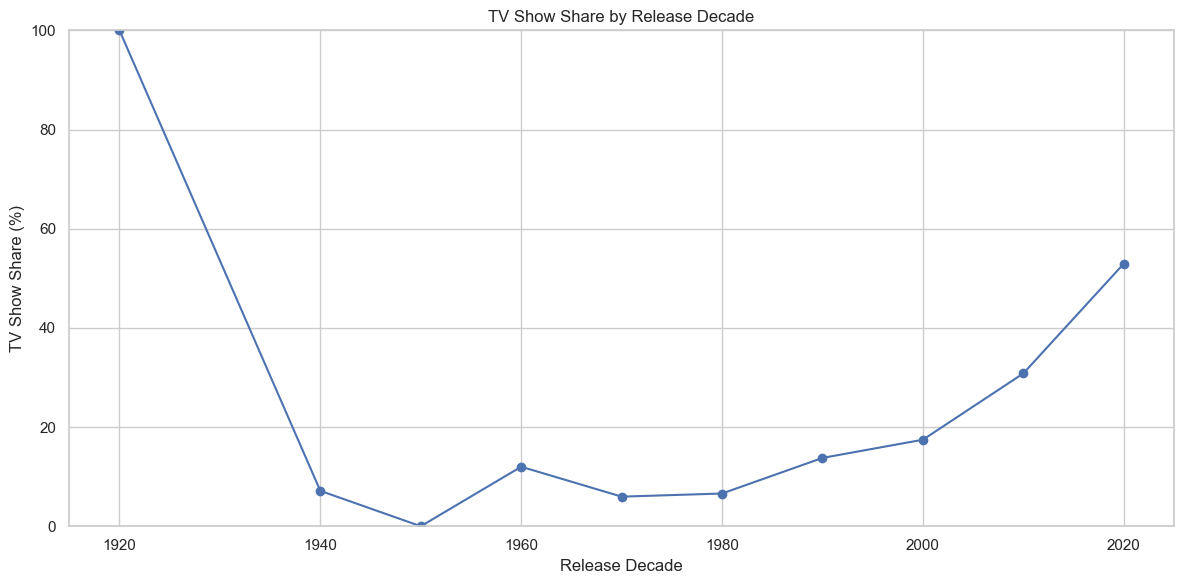

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(
    tv_share_by_decade.index,
    tv_share_by_decade.values,
    marker="o"
)

plt.title("TV Show Share by Release Decade")
plt.xlabel("Release Decade")
plt.ylabel("TV Show Share (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 6.3 Country × Content Type

Because some countries have very few titles, country-level percentages can become misleading. The full cross-tabulation is retained, but a **minimum of 10 title occurrences** is used when examining country-level composition.

This threshold is used only to reduce small-sample noise; it does not alter the original dataset.


In [ ]:
country_type = (
    df.assign(country_split=df["country"].str.split(", "))
      .explode("country_split")
)

country_type_counts = pd.crosstab(
    country_type["country_split"],
    country_type["type"]
)

print("Country × Content Type — All Countries")
display(country_type_counts)

Country × Content Type — All Countries


type,Movie,TV Show
country_split,,
Afghanistan,1,0
Albania,1,0
Algeria,2,0
Angola,1,0
Argentina,64,18
...,...,...
Vatican City,1,0
Venezuela,3,0
Vietnam,5,0


In [ ]:
country_occurrences = country_type["country_split"].value_counts()

valid_countries = country_occurrences[
    (country_occurrences >= 10) &
    (country_occurrences.index != "Unknown")
].index

country_type_filtered = country_type[
    country_type["country_split"].isin(valid_countries)
]

country_type_filtered_pct = pd.crosstab(
    country_type_filtered["country_split"],
    country_type_filtered["type"],
    normalize="index"
).mul(100).round(2)

print("Country × Content Type — Countries with at least 10 title occurrences")
display(country_type_filtered_pct)

Country × Content Type — Countries with at least 10 title occurrences


type,Movie,TV Show
country_split,,
Argentina,78.05,21.95
Australia,58.33,41.67
Austria,90.91,9.09
Belgium,87.06,12.94
Brazil,67.05,32.95
Canada,69.42,30.58
Chile,80.77,19.23
China,69.39,30.61
Colombia,37.78,62.22


## 6.4 Genre × Rating

In [ ]:
genre_rating = (
    df.assign(genre=df["listed_in"].str.split(", "))
      .explode("genre")
)

print("Number of genres/categories:", genre_rating["genre"].nunique())

genre_rating_pct = pd.crosstab(
    genre_rating["genre"],
    genre_rating["rating"],
    normalize="index"
).mul(100).round(2)

display(genre_rating_pct)

Number of genres/categories: 42


rating,G,NC-17,NR,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV,UR,Unknown
genre,,,,,,,,,,,,,,,
Action & Adventure,0.14,0.00,1.25,3.19,16.37,23.72,25.94,0.00,25.10,3.88,0.00,0.00,0.14,0.28,0.00
Anime Features,0.00,0.00,0.00,8.77,7.02,0.00,24.56,0.00,22.81,29.82,0.00,7.02,0.00,0.00,0.00
Anime Series,0.00,0.00,0.00,0.00,0.00,0.00,39.86,0.00,33.78,10.14,0.68,14.86,0.00,0.00,0.68
British TV Shows,0.00,0.00,0.86,0.00,0.00,0.00,18.53,6.47,41.38,23.28,7.33,2.16,0.00,0.00,0.00
Children & Family Movies,5.83,0.00,0.00,31.20,2.07,0.00,3.20,8.83,0.00,13.72,18.42,15.79,0.94,0.00,0.00
Classic & Cult TV,0.00,0.00,0.00,0.00,0.00,0.00,40.74,3.70,25.93,22.22,3.70,3.70,0.00,0.00,0.00
Classic Movies,6.80,0.00,2.91,12.62,8.74,26.21,20.39,0.97,10.68,10.68,0.00,0.00,0.00,0.00,0.00
Comedies,0.75,0.14,1.09,8.50,9.45,10.40,28.82,1.84,25.42,9.93,1.16,2.11,0.27,0.14,0.00
Crime TV Shows,0.00,0.00,0.23,0.00,0.00,0.00,24.36,0.23,73.54,0.94,0.00,0.70,0.00,0.00,0.00


In [ ]:
dominant_rating = genre_rating_pct.idxmax(axis=1)
dominant_percentage = genre_rating_pct.max(axis=1).round(2)

genre_rating_summary = pd.DataFrame({
    "Dominant Rating": dominant_rating,
    "Percentage": dominant_percentage
}).sort_values("Percentage", ascending=False)

print("Dominant rating associated with each genre/category:")
display(genre_rating_summary)

Dominant rating associated with each genre/category:


,Dominant Rating,Percentage
genre,,
Stand-Up Comedy,TV-MA,85.41
TV Horror,TV-MA,76.81
Crime TV Shows,TV-MA,73.54
Spanish-Language TV Shows,TV-MA,71.43
Stand-Up Comedy & Talk Shows,TV-MA,69.23
TV Mysteries,TV-MA,67.78
TV Thrillers,TV-MA,64.00
LGBTQ Movies,TV-MA,58.89
TV Dramas,TV-MA,56.39


## 6.5 Release Decade × Rating

Year-by-year rating tables are too granular for interpretation. Release decades provide a more stable view of how rating composition changes over time.

For visualization, the major rating categories are shown separately from the full calculation.


In [ ]:
decade_rating_counts = pd.crosstab(
    df["release_decade"],
    df["rating"]
)

decade_rating_pct = pd.crosstab(
    df["release_decade"],
    df["rating"],
    normalize="index"
).mul(100).round(2)

print("Release Decade × Rating — Counts")
display(decade_rating_counts)

print("Release Decade × Rating — Percentages")
display(decade_rating_pct)

Release Decade × Rating — Counts


rating,G,NC-17,NR,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV,UR,Unknown
release_decade,,,,,,,,,,,,,,,
1920,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
1940,0,0,0,0,0,0,7,0,1,6,0,0,0,0,0
1950,2,0,1,0,1,0,5,1,0,1,0,0,0,0,0
1960,2,0,0,0,2,4,7,1,3,6,0,0,0,0,0
1970,4,0,1,10,1,12,15,1,11,11,0,0,0,1,0
1980,2,0,3,9,7,14,43,0,13,13,0,2,0,0,0
1990,5,0,3,15,40,53,49,10,29,12,2,7,0,0,0
2000,13,0,6,63,115,115,200,5,103,75,7,23,0,3,0
2010,9,3,70,136,201,425,1447,135,2262,610,202,197,6,1,7


Release Decade × Rating — Percentages


rating,G,NC-17,NR,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV,UR,Unknown
release_decade,,,,,,,,,,,,,,,
1920,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1940,0.00,0.00,0.00,0.00,0.00,0.00,50.00,0.00,7.14,42.86,0.00,0.00,0.00,0.00,0.00
1950,18.18,0.00,9.09,0.00,9.09,0.00,45.45,9.09,0.00,9.09,0.00,0.00,0.00,0.00,0.00
1960,8.00,0.00,0.00,0.00,8.00,16.00,28.00,4.00,12.00,24.00,0.00,0.00,0.00,0.00,0.00
1970,5.97,0.00,1.49,14.93,1.49,17.91,22.39,1.49,16.42,16.42,0.00,0.00,0.00,1.49,0.00
1980,1.89,0.00,2.83,8.49,6.60,13.21,40.57,0.00,12.26,12.26,0.00,1.89,0.00,0.00,0.00
1990,2.22,0.00,1.33,6.67,17.78,23.56,21.78,4.44,12.89,5.33,0.89,3.11,0.00,0.00,0.00
2000,1.79,0.00,0.82,8.65,15.80,15.80,27.47,0.69,14.15,10.30,0.96,3.16,0.00,0.41,0.00
2010,0.16,0.05,1.23,2.38,3.52,7.44,25.34,2.36,39.61,10.68,3.54,3.45,0.11,0.02,0.12


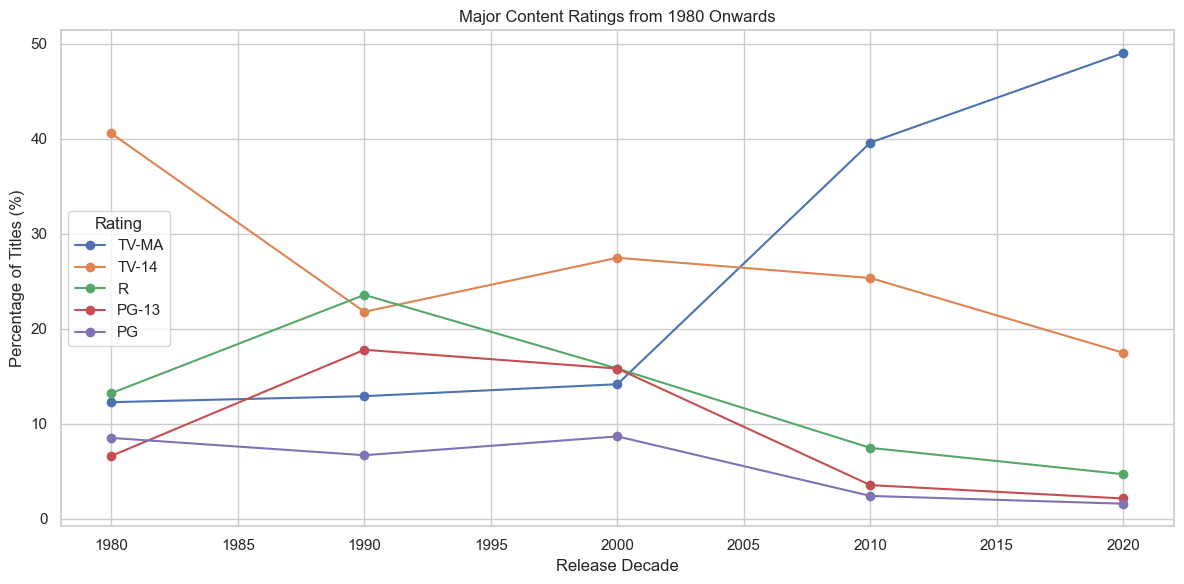

In [ ]:
major_ratings = ["TV-MA", "TV-14", "R", "PG-13", "PG"]

available_major_ratings = [
    rating for rating in major_ratings
    if rating in decade_rating_pct.columns
]

recent_decades = decade_rating_pct.loc[
    decade_rating_pct.index >= 1980,
    available_major_ratings
]

recent_decades.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("Major Content Ratings from 1980 Onwards")
plt.xlabel("Release Decade")
plt.ylabel("Percentage of Titles (%)")
plt.legend(title="Rating")
plt.tight_layout()
plt.show()

## 7. Statistical Hypothesis Testing

The tests below evaluate selected relationships observed during EDA. Interpret p-values alongside effect size and test assumptions.

In [ ]:

from scipy.stats import mannwhitneyu

# Separate release years by content type
movie_years = df.loc[
    df["type"] == "Movie", "release_year"
]

tv_years = df.loc[
    df["type"] == "TV Show", "release_year"
]

# Perform hypothesis test
statistic, p_value = mannwhitneyu(
    movie_years,
    tv_years,
    alternative="two-sided"
)

print("Movie median release year:", movie_years.median())
print("TV Show median release year:", tv_years.median())
print("Mann-Whitney U statistic:", statistic)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0: Release-year distributions differ.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")


Movie median release year: 2016.0
TV Show median release year: 2018.0
Mann-Whitney U statistic: 4666841.5
P-value: 7.507433995099372e-88
Reject H0: Release-year distributions differ.


In [ ]:

import pandas as pd
from scipy.stats import chi2_contingency

# Create a contingency table
contingency_table = pd.crosstab(
    df["type"],
    df["rating"]
)

print("Contingency Table:")
display(contingency_table)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)

print(
    "Expected cell counts below 5:",
    (expected < 5).sum(),
    "out of",
    expected.size
)

alpha = 0.05

if p_value < alpha:
    print("Reject H0: Content type and rating are associated.")
else:
    print("Fail to reject H0: Insufficient evidence of an association.")


Contingency Table:


rating,G,NC-17,NR,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV,UR,Unknown
type,,,,,,,,,,,,,,,
Movie,39,3,79,247,386,663,1272,111,1845,505,117,95,5,5,5
TV Show,0,0,5,0,0,2,659,83,1018,301,163,176,1,0,2


Chi-square statistic: 931.8954923986923
Degrees of freedom: 14
P-value: 6.306265095860963e-190
Expected cell counts below 5: 8 out of 30
Reject H0: Content type and rating are associated.


In [ ]:
print("Minimum expected count:", expected.min())
print("Expected counts below 1:", (expected < 1).sum())

Minimum expected count: 0.9284705278027482
Expected counts below 1: 1


In [ ]:
import numpy as np

n = contingency_table.to_numpy().sum()
r, k = contingency_table.shape

cramers_v = np.sqrt(
    chi2 / (n * min(r - 1, k - 1))
)

print("Cramér's V:", cramers_v)

Cramér's V: 0.3459381974730075


## 8. Multivariate Exploratory Analysis

These visualizations examine content type, release decade, and rating together. They are descriptive rather than causal.

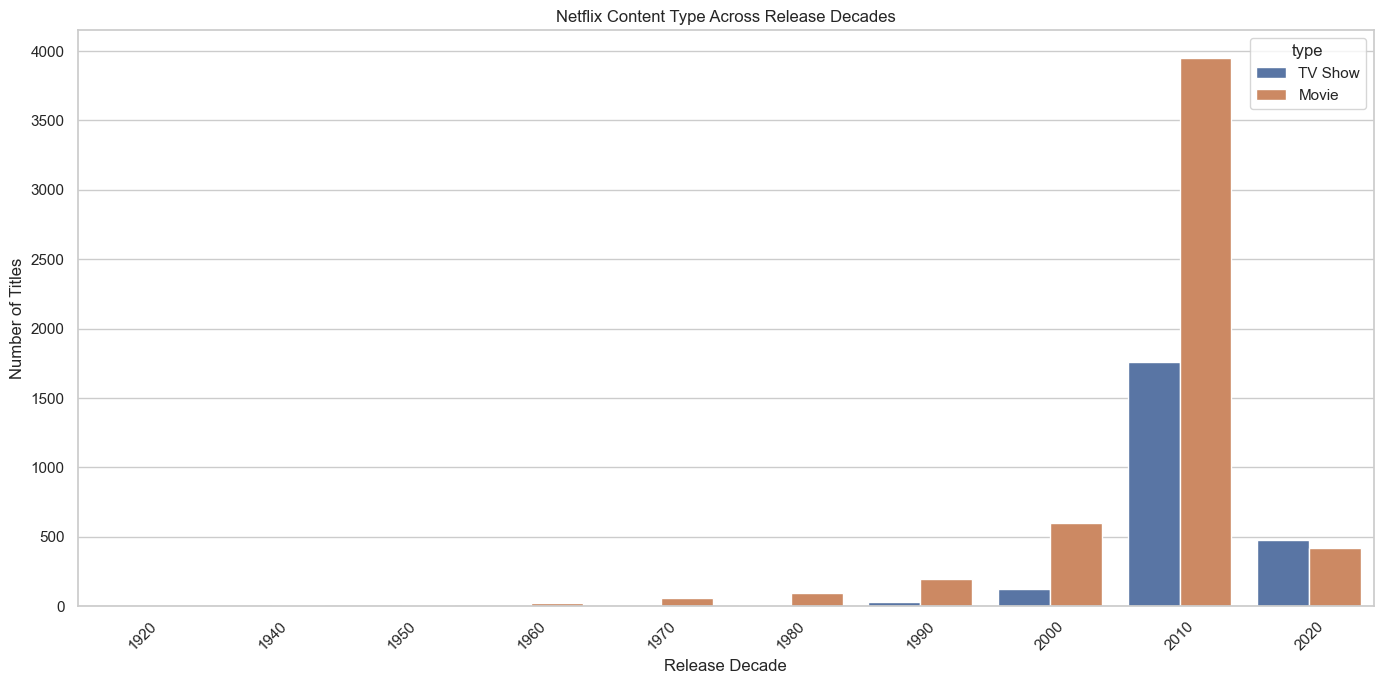

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create a working copy
mv_df = df[["type", "release_year", "rating"]].copy()

# Remove missing values for this analysis
mv_df = mv_df.dropna(
    subset=["type", "release_year", "rating"]
)

# Group release years into decades
mv_df["release_decade"] = (
    mv_df["release_year"] // 10
) * 10

# Create a joint visualization
plt.figure(figsize=(14, 7))

sns.countplot(
    data=mv_df,
    x="release_decade",
    hue="type"
)

plt.title("Netflix Content Type Across Release Decades")
plt.xlabel("Release Decade")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


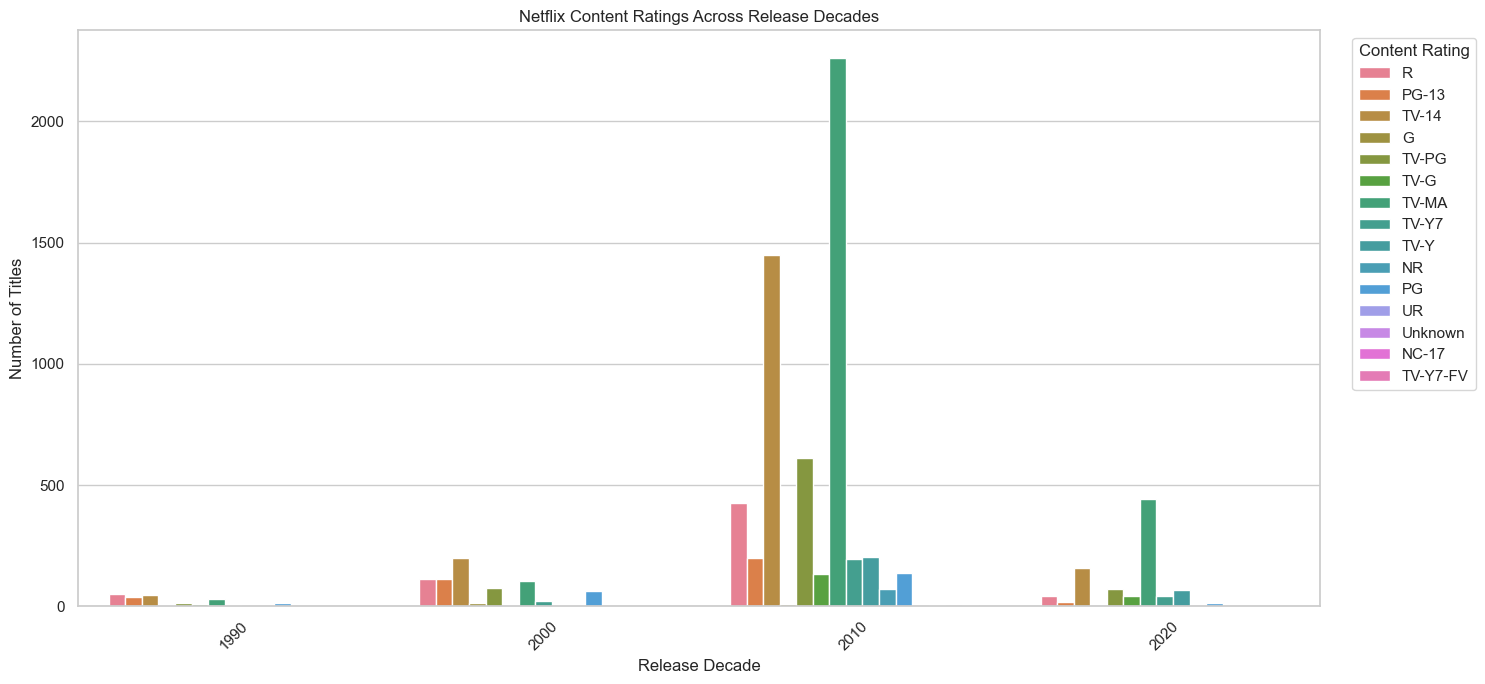

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Keep only the most recent decades with meaningful representation
rating_mv = mv_df[
    mv_df["release_decade"].between(1990, 2020)
].copy()

plt.figure(figsize=(15, 7))

sns.countplot(
    data=rating_mv,
    x="release_decade",
    hue="rating"
)

plt.title("Netflix Content Ratings Across Release Decades")
plt.xlabel("Release Decade")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.legend(
    title="Content Rating",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


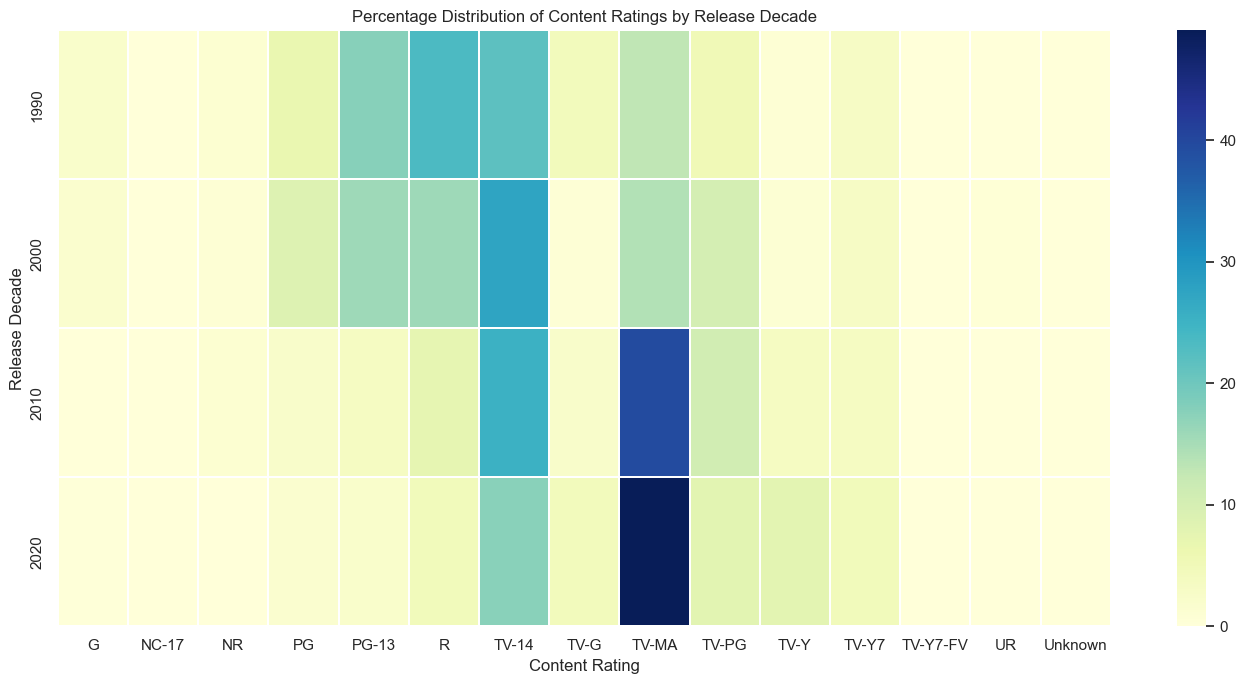

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rating_table = pd.crosstab(
    rating_mv["release_decade"],
    rating_mv["rating"],
    normalize="index"
) * 100

plt.figure(figsize=(14, 7))

sns.heatmap(
    rating_table,
    cmap="YlGnBu",
    annot=False,
    linewidths=0.3
)

plt.title("Percentage Distribution of Content Ratings by Release Decade")
plt.xlabel("Content Rating")
plt.ylabel("Release Decade")
plt.tight_layout()
plt.show()


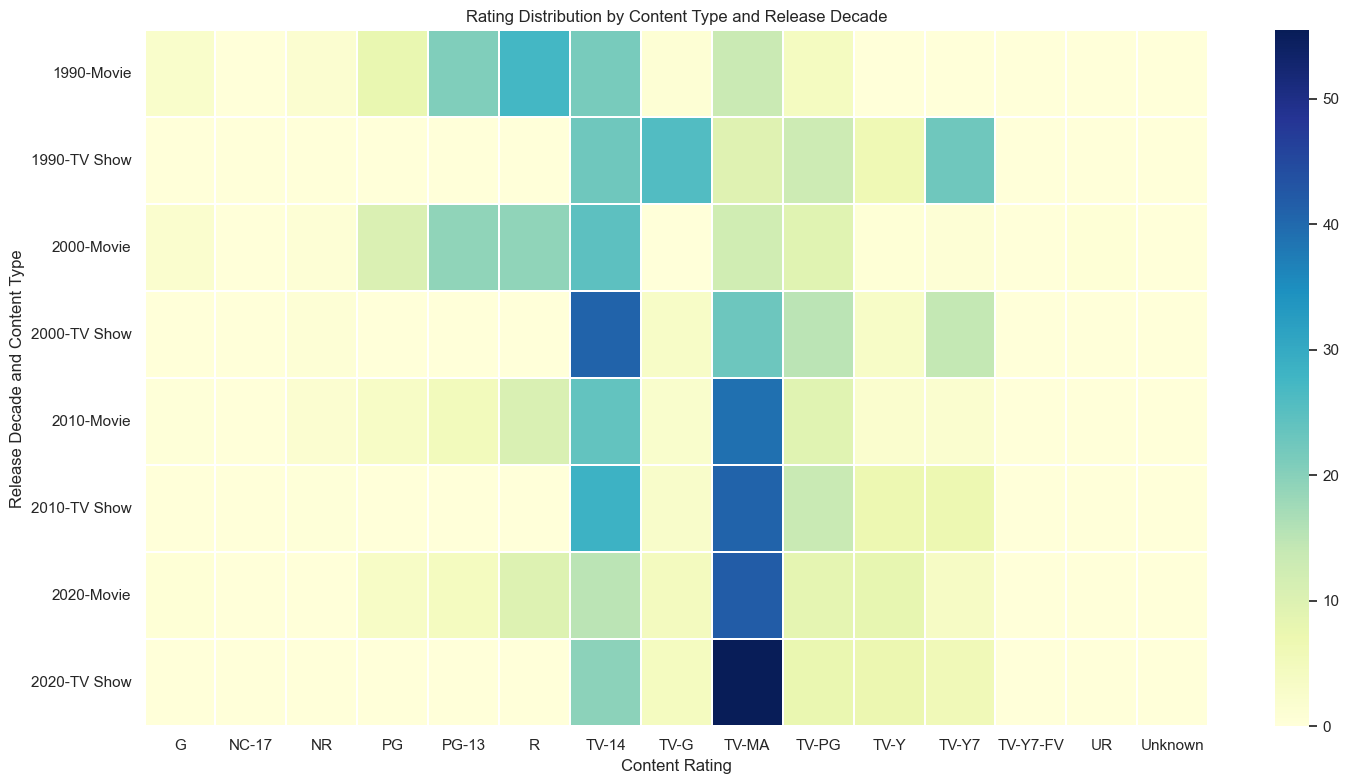

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Build a three-variable count table
type_rating_decade = pd.crosstab(
    [
        rating_mv["release_decade"],
        rating_mv["type"]
    ],
    rating_mv["rating"],
    normalize="index"
) * 100

plt.figure(figsize=(15, 8))

sns.heatmap(
    type_rating_decade,
    cmap="YlGnBu",
    annot=False,
    linewidths=0.3
)

plt.title(
    "Rating Distribution by Content Type and Release Decade"
)
plt.xlabel("Content Rating")
plt.ylabel("Release Decade and Content Type")
plt.tight_layout()
plt.show()


## Key Findings from Exploratory Data Analysis

The exploratory analysis and statistical tests provide the following findings:

1. **Release-year differences:** The median release year was 2016 for movies and 2018 for TV shows. The Mann–Whitney U test returned a p-value of approximately \(7.51 \times 10^{-88}\), indicating a statistically significant difference between their release-year distributions.

2. **Association between content type and rating:** The chi-square test returned a statistic of 931.90 with 14 degrees of freedom and a p-value of approximately \(6.31 \times 10^{-190}\). Cramér's V was 0.346, indicating an association between content type and rating. Some expected cell counts were small, so the chi-square assumptions should be reviewed before drawing a firm inferential conclusion.

3. **Catalogue diversity:** The dataset contains multiple genres and country labels, demonstrating diversity in the catalogue. Since a title may belong to several genres or countries, these categories are not mutually exclusive.

### Interpretation

The EDA establishes that the Netflix catalogue has varied content characteristics and statistically detectable differences in selected attributes. These observations motivate further analysis using numerical feature representations and clustering.

The findings describe patterns in the available catalogue; they do not establish causal relationships or explain individual viewing preferences.


## 9. Feature Engineering and Representation

This section engineers several features for catalogue analysis and builds the numerical representation used for clustering.

- **Duration features:** Extracted to analyse movie runtimes and TV-show seasons.
- **Date-added features:** Extracted to analyse when titles were added to Netflix.
- **Genre features:** Multi-hot encoded to represent each title's categories.
- **Description features:** Converted into TF-IDF vectors to represent textual content.

The clustering feature matrix `X_features` combines only the genre indicators and description TF-IDF features. Duration and date-added features are engineered for exploratory analysis but are not included in this clustering matrix.


In [ ]:

# FEATURE ENGINEERING: DURATION

# Extract numerical duration
df["duration_value"] = pd.to_numeric(
    df["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Extract duration unit
df["duration_unit"] = (
    df["duration"]
    .str.extract(r"\d+\s*(.*)")[0]
    .str.strip()
)

# Separate movie runtime and TV Show seasons
df["movie_runtime_min"] = df["duration_value"].where(
    df["type"] == "Movie"
)

df["tv_seasons"] = df["duration_value"].where(
    df["type"] == "TV Show"
)

# Verify the transformation
display(
    df[[
        "type",
        "duration",
        "duration_value",
        "duration_unit",
        "movie_runtime_min",
        "tv_seasons"
    ]].head(10)
)

print("Unparsed durations:", df["duration_value"].isna().sum())
print("\nDuration units:")
display(df["duration_unit"].value_counts(dropna=False))


,type,duration,duration_value,duration_unit,movie_runtime_min,tv_seasons
0,TV Show,4 Seasons,4,Seasons,NaN,4.0
1,Movie,93 min,93,min,93.0,NaN
2,Movie,78 min,78,min,78.0,NaN
3,Movie,80 min,80,min,80.0,NaN
4,Movie,123 min,123,min,123.0,NaN
5,TV Show,1 Season,1,Season,NaN,1.0
6,Movie,95 min,95,min,95.0,NaN
7,Movie,119 min,119,min,119.0,NaN
8,Movie,118 min,118,min,118.0,NaN
9,Movie,143 min,143,min,143.0,NaN


Unparsed durations: 0

Duration units:


duration_unit
min        5377
Season     1608
Seasons     802
Name: count, dtype: int64

In [ ]:

# FEATURE ENGINEERING: DATE ADDED

# Convert date_added to datetime
df["date_added"] = pd.to_datetime(
    df["date_added"].replace("Unknown", pd.NA),
    errors="coerce"
)

# Extract year and month
df["date_added_year"] = df["date_added"].dt.year
df["date_added_month"] = df["date_added"].dt.month

# Inspect the results
display(
    df[[
        "title",
        "date_added",
        "date_added_year",
        "date_added_month"
    ]].head(10)
)

print("Missing dates after conversion:", df["date_added"].isna().sum())


,title,date_added,date_added_year,date_added_month
0,3%,2020-08-14,2020.0,8.0
1,7:19,2016-12-23,2016.0,12.0
2,23:59,2018-12-20,2018.0,12.0
3,9,2017-11-16,2017.0,11.0
4,21,2020-01-01,2020.0,1.0
5,46,2017-07-01,2017.0,7.0
6,122,2020-06-01,2020.0,6.0
7,187,2019-11-01,2019.0,11.0
8,706,2019-04-01,2019.0,4.0
9,1920,2017-12-15,2017.0,12.0


Missing dates after conversion: 98


In [ ]:

# FEATURE ENGINEERING: GENRE CATEGORIES

from sklearn.preprocessing import MultiLabelBinarizer

# Split each title's genre/category string into a list
genre_lists = (
    df["listed_in"]
    .fillna("Unknown")
    .str.split(", ")
)

# Convert multi-label categories into binary columns
mlb = MultiLabelBinarizer()
genre_encoded = mlb.fit_transform(genre_lists)

genre_df = pd.DataFrame(
    genre_encoded,
    columns=[f"genre_{g}" for g in mlb.classes_],
    index=df.index
)

print("Number of unique genres/categories:", len(mlb.classes_))
print("Genre feature matrix shape:", genre_df.shape)
display(genre_df.head())


Number of unique genres/categories: 42
Genre feature matrix shape: (7787, 42)


,genre_Action & Adventure,genre_Anime Features,genre_Anime Series,genre_British TV Shows,genre_Children & Family Movies,genre_Classic & Cult TV,genre_Classic Movies,genre_Comedies,genre_Crime TV Shows,genre_Cult Movies,genre_Documentaries,genre_Docuseries,genre_Dramas,genre_Faith & Spirituality,genre_Horror Movies,genre_Independent Movies,genre_International Movies,genre_International TV Shows,genre_Kids' TV,genre_Korean TV Shows,genre_LGBTQ Movies,genre_Movies,genre_Music & Musicals,genre_Reality TV,genre_Romantic Movies,genre_Romantic TV Shows,genre_Sci-Fi & Fantasy,genre_Science & Nature TV,genre_Spanish-Language TV Shows,genre_Sports Movies,genre_Stand-Up Comedy,genre_Stand-Up Comedy & Talk Shows,genre_TV Action & Adventure,genre_TV Comedies,genre_TV Dramas,genre_TV Horror,genre_TV Mysteries,genre_TV Sci-Fi & Fantasy,genre_TV Shows,genre_TV Thrillers,genre_Teen TV Shows,genre_Thrillers
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:

# FEATURE ENGINEERING: DESCRIPTION TEXT USING TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=3000,
    ngram_range=(1, 2),
    min_df=2
)

description_tfidf = tfidf.fit_transform(
    df["description"].fillna("")
)

print("TF-IDF matrix shape:", description_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))
print("Sparse matrix:", description_tfidf.__class__.__name__)


TF-IDF matrix shape: (7787, 3000)
Vocabulary size: 3000
Sparse matrix: csr_matrix


In [ ]:

# FEATURE ENGINEERING: COMBINE GENRE AND DESCRIPTION FEATURES

from scipy.sparse import hstack, csr_matrix

genre_sparse = csr_matrix(genre_df.values)

X_features = hstack(
    [description_tfidf, genre_sparse],
    format="csr"
)

print("Combined feature matrix shape:", X_features.shape)
print("Matrix type:", X_features.__class__.__name__)
print("Total titles:", X_features.shape[0])
print("Total features:", X_features.shape[1])
print("Non-zero values:", X_features.nnz)


Combined feature matrix shape: (7787, 3042)
Matrix type: csr_matrix
Total titles: 7787
Total features: 3042
Non-zero values: 97452


## Machine Learning Approach

This project uses unsupervised learning because the objective is to discover groups of similar Netflix titles rather than predict a predefined target label.

Genre information is converted into binary features, while textual descriptions are represented using TF-IDF. These representations are combined into a feature matrix and reduced to 50 components using Truncated Singular Value Decomposition (TruncatedSVD).

The reduced representation is used to compare MiniBatch K-Means, Bisecting K-Means, Agglomerative Clustering, and DBSCAN.

The resulting clusters are evaluated using internal clustering metrics and inspected using their genre distributions and representative titles. This allows both numerical cluster quality and practical interpretability to be considered.

## 10. Prepare a Reproducible Evaluation Sample

Create one fixed sample for computationally expensive clustering metrics and DBSCAN parameter exploration. Model fitting may still use the full dataset.

In [ ]:
# Fixed sample shared by clustering evaluation and DBSCAN tuning
rng = np.random.RandomState(42)
sample_size = min(1500, X_features.shape[0])
sample_indices = rng.choice(
    X_features.shape[0],
    size=sample_size,
    replace=False
)
X_sample = X_features[sample_indices]

print("Evaluation sample size:", sample_size)

Evaluation sample size: 1500


## 11. Model 1 — MiniBatch K-Means

Use the elbow curve and sampled silhouette scores to select a practical value of k, then fit and interpret the more robust candidate model.

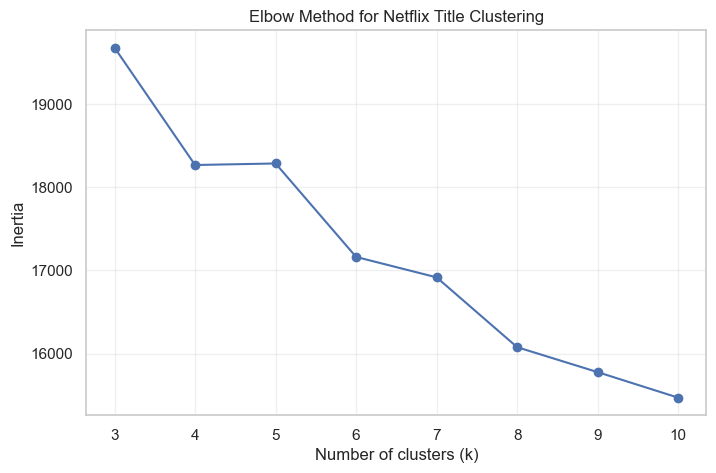

,k,inertia
0,3,19675.439968
1,4,18265.899028
2,5,18284.308354
3,6,17161.510163
4,7,16916.210968
5,8,16077.468103
6,9,15777.675787
7,10,15470.898508


In [ ]:

# CLUSTERING: FIND A REASONABLE NUMBER OF CLUSTERS

import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans

k_values = [3, 4, 5, 6, 7, 8, 9, 10]
inertias = []

for k in k_values:
    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=256,
        n_init=3
    )
    model.fit(X_features)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Netflix Title Clustering")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.show()

display(
    pd.DataFrame({
        "k": k_values,
        "inertia": inertias
    })
)


In [ ]:

# CLUSTERING EVALUATION: SILHOUETTE SCORE

import numpy as np
import pandas as pd
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

X_sample = X_features[sample_indices]

silhouette_results = []

for k in [4, 6, 8]:
    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=256,
        n_init=5,
        max_iter=200
    )

    model.fit(X_features)
    sample_labels = model.labels_[sample_indices]

    score = silhouette_score(
        X_sample,
        sample_labels,
        metric="cosine"
    )

    silhouette_results.append({
        "k": k,
        "silhouette_score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)
display(silhouette_df)


,k,silhouette_score
0,4,0.180683
1,6,0.177544
2,8,0.189112


In [ ]:

# MODEL COMPARISON: DESCRIPTION TF-IDF ONLY VS COMBINED FEATURES

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
from scipy.sparse import csr_matrix

comparison_results = []

# Reuse the same sample indices for a fair comparison
feature_sets = {
    "Description TF-IDF only": description_tfidf,
    "Description + genres": X_features
}

for feature_name, X in feature_sets.items():
    model = MiniBatchKMeans(
        n_clusters=8,
        random_state=42,
        batch_size=256,
        n_init=5,
        max_iter=200
    )

    model.fit(X)

    score = silhouette_score(
        X[sample_indices],
        model.labels_[sample_indices],
        metric="cosine"
    )

    comparison_results.append({
        "features": feature_name,
        "silhouette_score": score
    })

display(pd.DataFrame(comparison_results))


,features,silhouette_score
0,Description TF-IDF only,0.005002
1,Description + genres,0.189112


In [ ]:

# CLUSTER STABILITY: COMPARE TWO INITIALIZATIONS

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import adjusted_rand_score

model_a = MiniBatchKMeans(
    n_clusters=8,
    random_state=42,
    batch_size=256,
    n_init=5,
    max_iter=200
)

model_b = MiniBatchKMeans(
    n_clusters=8,
    random_state=21,
    batch_size=256,
    n_init=5,
    max_iter=200
)

labels_a = model_a.fit_predict(X_features)
labels_b = model_b.fit_predict(X_features)

ari = adjusted_rand_score(labels_a, labels_b)

print("Adjusted Rand Index (ARI):", round(ari, 4))


Adjusted Rand Index (ARI): 0.4844


In [ ]:

# STABILITY CHECK WITH MORE INITIALIZATIONS

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import adjusted_rand_score

stable_model_a = MiniBatchKMeans(
    n_clusters=8,
    random_state=42,
    batch_size=256,
    n_init=20,
    max_iter=300
)

stable_model_b = MiniBatchKMeans(
    n_clusters=8,
    random_state=21,
    batch_size=256,
    n_init=20,
    max_iter=300
)

stable_labels_a = stable_model_a.fit_predict(X_features)
stable_labels_b = stable_model_b.fit_predict(X_features)

stable_ari = adjusted_rand_score(
    stable_labels_a,
    stable_labels_b
)

print("ARI with n_init=20:", round(stable_ari, 4))


ARI with n_init=20: 0.6618


In [ ]:

# EVALUATE THE IMPROVED K=8 MODEL

df["cluster"] = stable_labels_a

cluster_sizes = (
    df["cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .to_frame("number_of_titles")
)

display(cluster_sizes)

print("Total assigned:", df["cluster"].notna().sum())
print("Number of clusters:", df["cluster"].nunique())


,number_of_titles
cluster,
0,1066
1,598
2,73
3,1795
4,1382
5,1941
6,329
7,603


Total assigned: 7787
Number of clusters: 8


In [ ]:

# INTERPRETATION OF THE IMPROVED CLUSTERING MODEL

for cluster_id in sorted(df["cluster"].unique()):
    print(f"\n{'=' * 60}")
    print(f"CLUSTER {cluster_id} — {sum(df['cluster'] == cluster_id)} titles")
    print(f"{'=' * 60}")

    sample = df.loc[
        df["cluster"] == cluster_id,
        ["title", "type", "listed_in", "description"]
    ].sample(
        n=min(5, (df["cluster"] == cluster_id).sum()),
        random_state=42
    )

    display(sample.reset_index(drop=True))



CLUSTER 0 — 1066 titles


,title,type,listed_in,description
0,A Futile and Stupid Gesture,Movie,Comedies,"In a brief life full of triumph and failure, ""National Lampoon"" co-founder Doug Kenney built a comedy empire, moldin..."
1,Stree,Movie,"Comedies, Horror Movies, Independent Movies","Once a year, men in a small town fear abduction by an eccentric female spirit. A young tailor dismisses the idea of ..."
2,It Takes Two,Movie,"Children & Family Movies, Comedies","The Olsen twins put a cute new spin on Mark Twain's classic tale ""The Prince and the Pauper,"" playing identical 9-ye..."
3,What Did I Mess,Movie,"Comedies, International Movies, Romantic Movies","In an attempt to get her ex to propose, Nayla hosts a gathering to introduce him to her new suitor — only for the pa..."
4,Spy Kids 3: Game Over,Movie,"Children & Family Movies, Comedies","Carmen gets caught in a virtual reality game designed by the kids' new nemesis, the Toymaker, and it's up to Juni to..."



CLUSTER 1 — 598 titles


,title,type,listed_in,description
0,Dennis and Gnasher Unleashed,TV Show,"British TV Shows, Kids' TV, TV Comedies","Fearless Dennis, his loyal dog Gnasher and best friends Rubi, JJ and Pieface quench their thirst for adventure by wr..."
1,Medical Police,TV Show,"Crime TV Shows, TV Action & Adventure, TV Comedies",Doctors Owen Maestro and Lola Spratt leave Childrens Hospital and join a secret arm of the CDC to investigate and de...
2,VeggieTales in the House,TV Show,Kids' TV,"Bob the Tomato, Larry the Cucumber and their Veggie pals venture beyond the kitchen counter in these playful adventu..."
3,Chewin' the Fat,TV Show,"British TV Shows, TV Comedies","Petty criminals, dodgy decorators, full-bore Glaswegians and oddball documentary presenters converge in this sketch ..."
4,Half & Half,TV Show,TV Comedies,"After two estranged half-sisters in their twenties find their lives suddenly entwined, they grow closer as they get ..."



CLUSTER 2 — 73 titles


...

,title,type,listed_in,description
0,The House Next Door,Movie,"Horror Movies, International Movies, Thrillers","In this Hindi version of ""Aval,"" a young couple's relationship is shaken to its core when a mysterious and troubled ..."
1,The Animal People,Movie,Documentaries,Animal rights protesters trying to shut down a facility that conducts animal testing are labeled terrorists by big b...
2,A Wrinkle in Time,Movie,Children & Family Movies,"Years after their father disappears, Meg and her younger brother Charles Wallace cross galaxies on a quest to save h..."
3,Marvel's The Punisher,TV Show,"Crime TV Shows, TV Action & Adventure, TV Thrillers",A former Marine out to punish the criminals responsible for his family's murder finds himself ensnared in a military...
4,My Little Pony Equestria Girls: Rollercoaster of Friendship,Movie,Children & Family Movies,"Rarity gets a summer job at Equestria Land, making Applejack feel jealous. But when their friends start vanishing, t..."



CLUSTER 6 — 329 titles


,title,type,listed_in,description
0,Alex Fernández: The Best Comedian in the World,Movie,Stand-Up Comedy,Comic Alex Fernández performs his familiar autobiographical stories but goes a little deeper this time with a tender...
1,Joe Mande’s Award-Winning Comedy Special,Movie,Stand-Up Comedy,"Stand-up comic Joe Mande aims for critical adulation with this special that covers dating shows, ""Shark Tank,"" Jewis..."
2,Jeff Foxworthy and Larry the Cable Guy: We’ve Been Thinking...,Movie,Stand-Up Comedy,Grammy-nominated comedians Jeff Foxworthy and Larry the Cable Guy bring their distinctive brand of humor to a packed...
3,Chelsea Peretti: One of the Greats,Movie,Stand-Up Comedy,"""Brooklyn Nine-Nine"" star Chelsea Peretti showcases her diverse talents in this dark yet silly reimagining of the co..."
4,Felix Lobrecht: Hype,Movie,Stand-Up Comedy,"Felix Lobrecht aims his dark humor at overly polite culture, weird laughter, the sheer awkwardness of a walking baby..."



CLUSTER 7 — 603 titles


,title,type,listed_in,description
0,Cloverfield,Movie,"Action & Adventure, Horror Movies, Sci-Fi & Fantasy",A going-away party in Manhattan is interrupted when a mysterious monster of epic proportions launches an attack on N...
1,The Lord of the Rings: The Two Towers,Movie,"Action & Adventure, Sci-Fi & Fantasy","Frodo and Sam head to Mordor to destroy the One Ring of Power while Gimli, Legolas and Aragorn search for the orc-ca..."
2,Tracers,Movie,Action & Adventure,"When a bike messenger falls into debt with organized criminals, a sexy woman draws him into her high-stakes world of..."
3,Bleach The Movie: Fade to Black,Movie,"Action & Adventure, Anime Features, Sci-Fi & Fantasy","When his mind is fogged by a scimitar-weilding stranger, Mayuri destroys his laboratory, unleashing a cloud of reish..."
4,Ghost Tears,Movie,"Action & Adventure, Anime Features, International Movies","As Motoko and Batou attempt to thwart a mysterious terrorist group, Togusa tracks the killer of a man with a prosthe..."


In [ ]:

# FINAL CANDIDATE EVALUATION

from sklearn.metrics import silhouette_score
import numpy as np

rng = np.random.RandomState(42)
sample_size = min(1500, X_features.shape[0])

sample_indices = rng.choice(
    X_features.shape[0],
    size=sample_size,
    replace=False
)

improved_silhouette = silhouette_score(
    X_features[sample_indices],
    stable_labels_a[sample_indices],
    metric="cosine"
)

print(
    "Silhouette score (improved K=8 model):",
    round(improved_silhouette, 6)
)


Silhouette score (improved K=8 model): 0.186212


## 12. Model 2 — Bisecting K-Means

Compare this divisive clustering method with MiniBatch K-Means using the same feature matrix and evaluation sample.

In [ ]:

# MODEL 2: BISECTING K-MEANS

from sklearn.cluster import BisectingKMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import pandas as pd

bisecting_model = BisectingKMeans(
    n_clusters=8,
    random_state=42,
    init="k-means++",
    n_init=5,
    max_iter=100,
    bisecting_strategy="largest_cluster"
)

bisecting_labels = bisecting_model.fit_predict(X_features)

# Evaluate on the same sample used for the improved K-Means model
bisecting_silhouette = silhouette_score(
    X_features[sample_indices],
    bisecting_labels[sample_indices],
    metric="cosine"
)

print("Bisecting K-Means silhouette score:",
      round(bisecting_silhouette, 6))

print("\nCluster sizes:")
display(
    pd.Series(bisecting_labels, name="cluster")
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .to_frame("number_of_titles")
)

# Compare both models
comparison = pd.DataFrame([
    {
        "model": "MiniBatch K-Means",
        "clusters": len(set(stable_labels_a)),
        "silhouette_score": improved_silhouette
    },
    {
        "model": "Bisecting K-Means",
        "clusters": len(set(bisecting_labels)),
        "silhouette_score": bisecting_silhouette
    }
])

print("\nModel comparison:")
display(comparison)


Bisecting K-Means silhouette score: 0.173642

Cluster sizes:


,number_of_titles
cluster,
0,414
1,546
2,1831
3,521
4,1227
5,811
6,1052
7,1385



Model comparison:


,model,clusters,silhouette_score
0,MiniBatch K-Means,8,0.186212
1,Bisecting K-Means,8,0.173642


## 13. Dimensionality Reduction with Truncated SVD

Truncated SVD reduces the sparse combined text-and-genre matrix to 50 components. This reduced representation is used by Agglomerative Clustering and DBSCAN.

In [ ]:

from sklearn.decomposition import TruncatedSVD

# Apply Truncated SVD to the COMBINED feature matrix
svd = TruncatedSVD(
    n_components=50,
    random_state=42,
    n_iter=7
)

X_reduced = svd.fit_transform(X_features)

print("Original shape:", X_features.shape)
print("Reduced shape:", X_reduced.shape)
print(
    "Explained variance ratio:",
    round(svd.explained_variance_ratio_.sum(), 4)
)


Original shape: (7787, 3042)
Reduced shape: (7787, 50)
Explained variance ratio: 0.669


## 14. Model 3 — Agglomerative Clustering

Ward linkage is used on the reduced SVD representation. Its Euclidean silhouette score should not be directly ranked against cosine scores computed on the original sparse matrix.

In [ ]:

# MODEL 3: AGGLOMERATIVE CLUSTERING

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import pandas as pd

agglomerative_model = AgglomerativeClustering(
    n_clusters=8,
    linkage="ward"
)

agglomerative_labels = agglomerative_model.fit_predict(X_reduced)

print("Number of clusters:", len(set(agglomerative_labels)))

print("\nCluster sizes:")
display(
    pd.Series(agglomerative_labels, name="cluster")
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .to_frame("number_of_titles")
)

# Evaluate on the same sampled rows
agglomerative_silhouette = silhouette_score(
    X_reduced[sample_indices],
    agglomerative_labels[sample_indices],
    metric="euclidean"
)

print(
    "\nAgglomerative silhouette score:",
    round(agglomerative_silhouette, 6)
)


Number of clusters: 8

Cluster sizes:


,number_of_titles
cluster,
0,1411
1,1068
2,1636
3,586
4,953
5,1378
6,389
7,366



Agglomerative silhouette score: 0.165283


## 15. Model 4 — DBSCAN Parameter Search and Interpretation

DBSCAN is tuned on the fixed sample in normalized SVD space. Silhouette is calculated on non-noise points only, so interpret it together with the number of clusters and noise percentage.

In [ ]:

# MODEL 4: DBSCAN PARAMETER EXPERIMENT

from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

# Use the same reproducible sample for parameter exploration
X_dbscan_sample = X_reduced[sample_indices]

# Normalize each sample vector to unit length.
# This makes Euclidean distance more comparable to cosine-based
# similarity for nonzero vectors.
X_dbscan_sample_norm = X_dbscan_sample / np.maximum(
    np.linalg.norm(X_dbscan_sample, axis=1, keepdims=True),
    1e-12
)

dbscan_results = []

for eps in [0.3, 0.5, 0.7, 0.9]:
    for min_samples in [5, 10]:
        model = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric="euclidean"
        )

        labels = model.fit_predict(X_dbscan_sample_norm)

        non_noise = labels != -1
        clusters_found = len(set(labels)) - (1 if -1 in labels else 0)
        noise_pct = 100 * np.mean(labels == -1)

        # Silhouette requires at least 2 clusters among non-noise points
        if (
            clusters_found >= 2
            and non_noise.sum() > clusters_found
            and len(np.unique(labels[non_noise])) >= 2
        ):
            score = silhouette_score(
                X_dbscan_sample_norm[non_noise],
                labels[non_noise],
                metric="euclidean"
            )
        else:
            score = np.nan

        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters_found": clusters_found,
            "noise_percent": round(noise_pct, 2),
            "silhouette_non_noise": (
                round(score, 4) if np.isfinite(score) else np.nan
            )
        })

display(pd.DataFrame(dbscan_results))


,eps,min_samples,clusters_found,noise_percent,silhouette_non_noise
0,0.3,5,71,23.40,0.7991
1,0.3,10,44,34.40,0.8025
2,0.5,5,71,22.93,0.7952
3,0.5,10,44,33.87,0.7985
4,0.7,5,20,4.27,0.0667
5,0.7,10,17,6.60,0.0858
6,0.9,5,3,0.27,0.1457
7,0.9,10,3,0.27,0.1457


In [ ]:

# DBSCAN: TEST A LARGER EPS VALUE

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

dbscan_results = []

for eps in [0.5, 0.6, 0.7, 0.8, 0.9]:
    model = DBSCAN(
        eps=eps,
        min_samples=10,
        metric="euclidean"
    )

    labels = model.fit_predict(X_dbscan_sample_norm)

    noise_mask = labels == -1
    valid_labels = labels[~noise_mask]
    n_clusters = len(set(valid_labels))
    noise_pct = 100 * noise_mask.mean()

    if n_clusters >= 2:
        score = silhouette_score(
            X_dbscan_sample_norm[~noise_mask],
            valid_labels,
            metric="euclidean"
        )
    else:
        score = np.nan

    dbscan_results.append({
        "eps": eps,
        "clusters_found": n_clusters,
        "noise_percent": round(noise_pct, 2),
        "silhouette_non_noise": (
            round(score, 4) if np.isfinite(score) else np.nan
        )
    })

display(pd.DataFrame(dbscan_results))


,eps,clusters_found,noise_percent,silhouette_non_noise
0,0.5,44,33.87,0.7985
1,0.6,33,33.20,0.5905
2,0.7,17,6.60,0.0858
3,0.8,4,2.87,0.1150
4,0.9,3,0.27,0.1457


In [ ]:

# DBSCAN: INTERPRET CLUSTERS AND NOISE

from sklearn.cluster import DBSCAN
import pandas as pd
import numpy as np

def inspect_dbscan(eps, min_samples=10, top_clusters=5, titles_per_cluster=3):
    model = DBSCAN(
        eps=eps,
        min_samples=min_samples,
        metric="euclidean"
    )

    labels = model.fit_predict(X_dbscan_sample_norm)

    # Map sampled labels back to their original DataFrame rows
    sample_df = df.iloc[sample_indices].copy()
    sample_df["dbscan_cluster"] = labels

    n_clusters = len(set(labels)) - int(-1 in labels)
    noise_pct = 100 * np.mean(labels == -1)

    print(f"\n{'=' * 65}")
    print(f"DBSCAN RESULTS: eps={eps}, min_samples={min_samples}")
    print(f"Clusters: {n_clusters}")
    print(f"Noise: {(labels == -1).sum()} titles ({noise_pct:.2f}%)")
    print("=" * 65)

    sizes = (
        sample_df[sample_df["dbscan_cluster"] != -1]
        ["dbscan_cluster"]
        .value_counts()
    )

    for cluster_id in sizes.head(top_clusters).index:
        group = sample_df[
            sample_df["dbscan_cluster"] == cluster_id
        ]

        print(
            f"\nCluster {cluster_id} "
            f"({len(group)} titles)"
        )

        display(
            group[
                ["title", "type", "listed_in", "description"]
            ].head(titles_per_cluster)
        )

    # Inspect a few noise titles
    noise_df = sample_df[sample_df["dbscan_cluster"] == -1]

    print("\nExample noise titles:")
    display(
        noise_df[
            ["title", "type", "listed_in", "description"]
        ].head(5)
    )

inspect_dbscan(eps=0.5)
inspect_dbscan(eps=0.7)



DBSCAN RESULTS: eps=0.5, min_samples=10
Clusters: 44
Noise: 508 titles (33.87%)

Cluster 18 (64 titles)


,title,type,listed_in,description
453,American Anarchist,Movie,Documentaries,"This documentary profiles William Powell, who wrote the ""The Anarchist Cookbook"" in the early 1970s and spent his la..."
4526,NOVA: Decoding the Weather Machine,Movie,Documentaries,"Scientists investigate Earth’s climate machine, looking for clues across the globe, from Greenland’s ice sheet to th..."
2995,Inequality for All,Movie,Documentaries,Former U.S. Labor Secretary Robert Reich makes a compelling case about the serious crisis the U.S. faces due to the ...



Cluster 17 (56 titles)


,title,type,listed_in,description
23,​Mayurakshi,Movie,"Dramas, International Movies","When a middle-aged divorcee returns to Kolkata to visit his ailing father, long-buried memories resurface, bringing ..."
4556,O Silêncio do Céu,Movie,"Dramas, International Movies","After being raped in her home, a married woman chooses not to tell her husband, unaware that he has his own troubled..."
6509,The Iron Lady,Movie,"Dramas, International Movies","Margaret Thatcher, the first female prime minister of Britain, navigates a career destined to change the rules of le..."



Cluster 11 (54 titles)


...

,title,type,listed_in,description
453,American Anarchist,Movie,Documentaries,"This documentary profiles William Powell, who wrote the ""The Anarchist Cookbook"" in the early 1970s and spent his la..."
4526,NOVA: Decoding the Weather Machine,Movie,Documentaries,"Scientists investigate Earth’s climate machine, looking for clues across the globe, from Greenland’s ice sheet to th..."
2995,Inequality for All,Movie,Documentaries,Former U.S. Labor Secretary Robert Reich makes a compelling case about the serious crisis the U.S. faces due to the ...



Cluster 4 (54 titles)


,title,type,listed_in,description
3133,Jeff Dunham: All Over the Map,Movie,Stand-Up Comedy,"America's most beloved ventriloquist hits the road, bringing along all of his most popular pals, including Achmed, P..."
7719,Yoo Byung Jae: Too Much Information,Movie,Stand-Up Comedy,"""Saturday Night Live Korea"" writer-turned-comedian Yoo Byung-jae lays bare his childhood memories and philosophy on ..."
5356,Sam Jay: 3 In The Morning,Movie,Stand-Up Comedy,"Comedian and ""Saturday Night Live"" writer Sam Jay serves up fresh takes on relationships, travel nightmares, the aud..."



Example noise titles:


,title,type,listed_in,description
101,3 Seconds Divorce,Movie,"Documentaries, Faith & Spirituality","A Muslim women's activist group in India protests against oral divorces, starting a movement to reclaim their religi..."
132,7 (Seven),TV Show,TV Shows,"Multiple women report their husbands as missing but when it appears they are looking for the same man, a police offi..."
4897,Pokémon the Movie: Power of Us,Movie,"Anime Features, Children & Family Movies","Ash and Pikachu journey to Fula City for its Wind Festival. When disaster looms, they must work together with a grou..."
7730,You vs. Wild,TV Show,"Kids' TV, Reality TV, Science & Nature TV","In this interactive series, you'll make key decisions to help Bear Grylls survive, thrive and complete missions in t..."
5294,Rugal,TV Show,"Crime TV Shows, International TV Shows, Korean TV Shows",A police detective who loses everything to a criminal organization seeks payback when he gains special abilities thr...


In [ ]:

from sklearn.cluster import DBSCAN
import pandas as pd
import numpy as np

eps = 0.7
min_samples = 10

dbscan_model = DBSCAN(
    eps=eps,
    min_samples=min_samples,
    metric="euclidean"
)

dbscan_labels = dbscan_model.fit_predict(X_dbscan_sample_norm)

dbscan_df = df.iloc[sample_indices][
    ["title", "type", "listed_in"]
].copy()

dbscan_df["cluster"] = dbscan_labels

# Cluster sizes, excluding noise
cluster_sizes = (
    dbscan_df[dbscan_df["cluster"] != -1]
    .groupby("cluster")
    .size()
    .sort_values(ascending=False)
)

print("Cluster sizes:")
display(cluster_sizes.rename("title_count").to_frame())

# Genre frequency within each cluster
print("Top genres in each of the five largest clusters:")

for cluster_id in cluster_sizes.head(5).index:
    genres = (
        dbscan_df.loc[
            dbscan_df["cluster"] == cluster_id,
            "listed_in"
        ]
        .dropna()
        .str.split(", ")
        .explode()
        .value_counts()
    )

    print(
        f"\nCluster {cluster_id} "
        f"({cluster_sizes[cluster_id]} titles)"
    )
    display(genres.head(8).rename("count").to_frame())

print("\nNoise titles:", (dbscan_labels == -1).sum())


Cluster sizes:


,title_count
cluster,
0,778
2,198
6,69
7,64
4,54
12,48
1,41
3,27
9,20


Top genres in each of the five largest clusters:

Cluster 0 (778 titles)


,count
listed_in,
International Movies,471
Dramas,393
Comedies,275
Independent Movies,143
Action & Adventure,120
Romantic Movies,113
Documentaries,86
Thrillers,78



Cluster 2 (198 titles)


...


Cluster 7 (64 titles)


,count
listed_in,
Documentaries,64



Cluster 4 (54 titles)


,count
listed_in,
Stand-Up Comedy,54



Noise titles: 99


## 16. Final Model Comparison and Conclusion

This section performs a standardized comparison of four clustering algorithms using the same evaluation sample and the same normalized 50-component SVD representation. This setup is distinct from earlier model-specific experiments, which may use different representations or evaluation settings.

The comparison uses internal clustering metrics and cluster-content inspection. DBSCAN noise points are reported separately, and its metrics are calculated only on non-noise titles; therefore, its metric values are not directly comparable with scores calculated on all titles by the other algorithms.


### 16.1 Verify the evaluation data

Check that the reduced matrix and fixed evaluation sample align before comparing models.

In [ ]:

# Section 16.1 — Verify evaluation data

print("Reduced feature matrix:", X_reduced.shape)
print("Evaluation sample size:", len(sample_indices))
print("Sampled feature matrix:", X_dbscan_sample_norm.shape)

assert X_reduced.shape[0] == len(df), \
    "X_reduced and df have different row counts."

assert len(sample_indices) == X_dbscan_sample_norm.shape[0], \
    "Sample indices and DBSCAN sample have different lengths."

assert X_reduced.shape[1] == 50, \
    "Expected 50 SVD components."

print("\nEvaluation data checks passed.")


Reduced feature matrix: (7787, 50)
Evaluation sample size: 1500
Sampled feature matrix: (1500, 50)

Evaluation data checks passed.


### 16.2 Normalize the evaluation matrix

Use the same normalized 50-component representation for each model in this comparison.

In [ ]:

from sklearn.preprocessing import normalize

# Use the same 1,500 titles for every model
X_eval = X_reduced[sample_indices]

# Normalize each title's feature vector
X_eval_norm = normalize(X_eval, norm="l2")

print("Evaluation matrix shape:", X_eval_norm.shape)
print("First 5 vector norms:",
      (X_eval_norm[:5] ** 2).sum(axis=1) ** 0.5)


Evaluation matrix shape: (1500, 50)
First 5 vector norms: [1. 1. 1. 1. 1.]


### 16.3 Fit the models on the same sample

Refit all four algorithms on the shared evaluation matrix with the documented parameters.

In [ ]:

from sklearn.cluster import MiniBatchKMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import pairwise_distances
from sklearn.preprocessing import normalize
from sklearn.cluster import BisectingKMeans

# 1. MiniBatch K-Means
mbk_eval = MiniBatchKMeans(
    n_clusters=8,
    random_state=42,
    batch_size=256,
    n_init=10,
    max_iter=300
)
labels_mbk = mbk_eval.fit_predict(X_eval_norm)

# 2. Bisecting K-Means
bisect_eval = BisectingKMeans(
    n_clusters=8,
    random_state=42
)
labels_bisect = bisect_eval.fit_predict(X_eval_norm)

# 3. Agglomerative Clustering
agg_eval = AgglomerativeClustering(
    n_clusters=8,
    linkage="ward"
)
labels_agg = agg_eval.fit_predict(X_eval_norm)

# 4. DBSCAN
dbscan_eval = DBSCAN(
    eps=0.7,
    min_samples=10,
    metric="euclidean"
)
labels_dbscan = dbscan_eval.fit_predict(X_eval_norm)

# Summarize generated labels
label_sets = {
    "MiniBatch K-Means": labels_mbk,
    "Bisecting K-Means": labels_bisect,
    "Agglomerative": labels_agg,
    "DBSCAN": labels_dbscan
}

for name, labels in label_sets.items():
    clusters = set(labels) - {-1}
    noise_count = (labels == -1).sum()

    print(
        f"{name}: {len(clusters)} clusters, "
        f"{noise_count} noise points, "
        f"{len(labels) - noise_count} assigned titles"
    )


MiniBatch K-Means: 8 clusters, 0 noise points, 1500 assigned titles
Bisecting K-Means: 8 clusters, 0 noise points, 1500 assigned titles
Agglomerative: 8 clusters, 0 noise points, 1500 assigned titles
DBSCAN: 17 clusters, 99 noise points, 1401 assigned titles


### 16.4 Compare internal clustering metrics

Silhouette and Calinski–Harabasz are higher-is-better; Davies–Bouldin is lower-is-better. DBSCAN metrics exclude noise points, so they are not strictly comparable with scores calculated over every sample.

In [ ]:

import pandas as pd
import numpy as np
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

def evaluate_clustering(X, labels, exclude_noise=False):
    labels = np.asarray(labels)

    # Exclude DBSCAN noise when requested
    if exclude_noise:
        mask = labels != -1
        X_eval_metric = X[mask]
        labels_metric = labels[mask]
    else:
        X_eval_metric = X
        labels_metric = labels

    n_clusters = len(set(labels_metric))

    # Silhouette and the other indices need at least
    # 2 clusters and fewer clusters than data points.
    if n_clusters < 2 or n_clusters >= len(labels_metric):
        return {
            "Silhouette Score": np.nan,
            "Davies-Bouldin Index": np.nan,
            "Calinski-Harabasz Index": np.nan
        }

    return {
        "Silhouette Score": silhouette_score(
            X_eval_metric, labels_metric, metric="euclidean"
        ),
        "Davies-Bouldin Index": davies_bouldin_score(
            X_eval_metric, labels_metric
        ),
        "Calinski-Harabasz Index": calinski_harabasz_score(
            X_eval_metric, labels_metric
        )
    }

evaluation_results = {}

for name, labels in label_sets.items():
    evaluation_results[name] = evaluate_clustering(
        X_eval_norm,
        labels,
        exclude_noise=(name == "DBSCAN")
    )

comparison_df = pd.DataFrame(evaluation_results).T

comparison_df["Clusters"] = [
    len(set(label_sets[name]) - {-1})
    for name in comparison_df.index
]

comparison_df["Noise (%)"] = [
    100 * np.mean(label_sets[name] == -1)
    for name in comparison_df.index
]

comparison_df = comparison_df[
    [
        "Clusters",
        "Noise (%)",
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Index"
    ]
]

display(comparison_df.round(4))


,Clusters,Noise (%),Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
MiniBatch K-Means,8,0.0,0.2660,1.6548,168.3906
Bisecting K-Means,8,0.0,0.2354,2.0799,153.4710
Agglomerative,8,0.0,0.2315,1.7912,145.9998
DBSCAN,17,6.6,0.0858,1.1295,64.7509


### 16.5 Visualize the comparison

Each metric is plotted separately to keep its scale and direction clear.

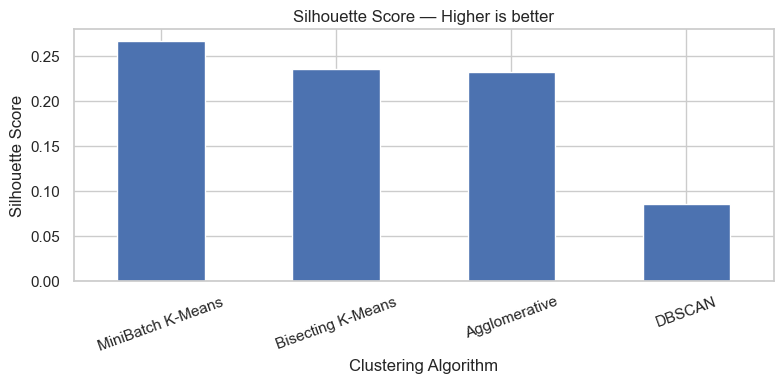

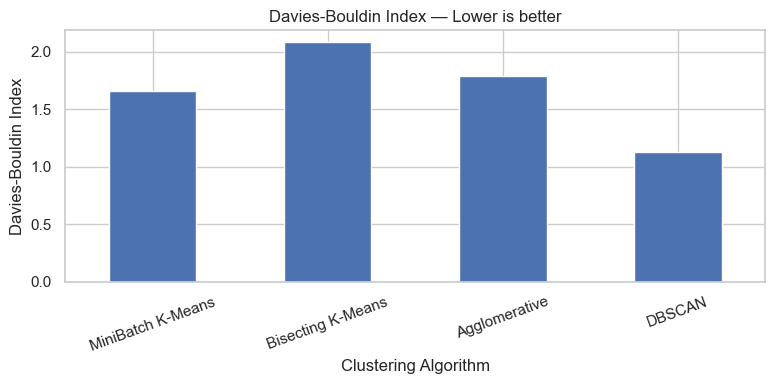

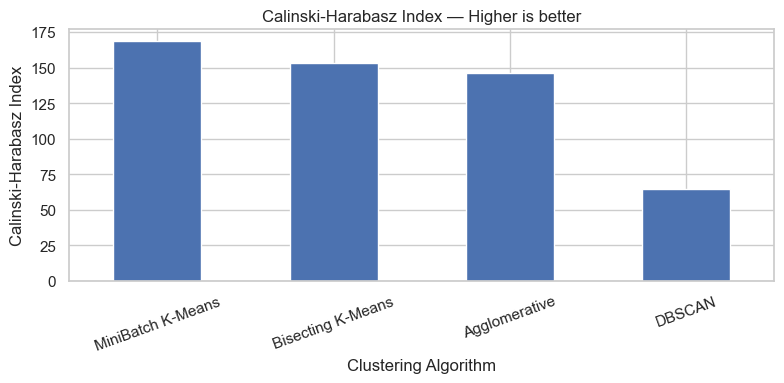

In [ ]:

import matplotlib.pyplot as plt

metrics_to_plot = [
    ("Silhouette Score", "Higher is better"),
    ("Davies-Bouldin Index", "Lower is better"),
    ("Calinski-Harabasz Index", "Higher is better")
]

for metric, direction in metrics_to_plot:
    ax = comparison_df[metric].plot(
        kind="bar",
        figsize=(8, 4),
        title=f"{metric} — {direction}"
    )

    ax.set_ylabel(metric)
    ax.set_xlabel("Clustering Algorithm")
    ax.tick_params(axis="x", rotation=20)

    plt.tight_layout()
    plt.show()


### 16.6 Inspect cluster contents

Compare the most common categories and representative titles. Genre counts may exceed cluster size because titles can have multiple categories.

In [ ]:

# Build metadata for the same evaluation sample
eval_titles = df.iloc[sample_indices][
    ["title", "type", "listed_in"]
].copy().reset_index(drop=True)

model_labels = {
    "MiniBatch K-Means": labels_mbk,
    "Bisecting K-Means": labels_bisect,
    "Agglomerative": labels_agg,
    "DBSCAN": labels_dbscan
}

for model_name, labels in model_labels.items():
    print(f"\n{'=' * 60}")
    print(model_name)
    print("=" * 60)

    temp = eval_titles.copy()
    temp["cluster"] = labels

    # Exclude DBSCAN noise from cluster interpretation
    temp = temp[temp["cluster"] != -1]

    for cluster_id in temp["cluster"].value_counts().index:
        group = temp[temp["cluster"] == cluster_id]

        genres = (
            group["listed_in"]
            .dropna()
            .str.split(", ")
            .explode()
            .value_counts()
        )

        print(
            f"\nCluster {cluster_id}: "
            f"{len(group)} titles"
        )
        print("Top genres:", genres.head(5).to_dict())
        print(
            "Representative titles:",
            group["title"].head(3).tolist()
        )



MiniBatch K-Means

Cluster 3: 356 titles
Top genres: {'International TV Shows': 228, 'TV Dramas': 123, 'Crime TV Shows': 73, 'Romantic TV Shows': 60, 'Docuseries': 59}
Representative titles: ['Lady, la vendedora de rosas', 'Goodbye My Wife', 'Last Tango in Halifax']

Cluster 1: 321 titles
Top genres: {'International Movies': 303, 'Dramas': 191, 'Comedies': 155, 'Romantic Movies': 92, 'Thrillers': 36}
Representative titles: ['Ravenous', 'Tere Naal Love Ho Gaya', 'Kaal']

Cluster 7: 241 titles
Top genres: {'Dramas': 181, 'Independent Movies': 136, 'Thrillers': 51, 'International Movies': 49, 'Comedies': 44}
Representative titles: ['Our Idiot Brother', 'Listen', 'Trespass Against Us']

Cluster 2: 154 titles
Top genres: {'Documentaries': 154, 'International Movies': 53, 'Music & Musicals': 22, 'Sports Movies': 18, 'LGBTQ Movies': 7}
Representative titles: ['Unchained: The Untold Story of Freestyle Motocross', '3 Seconds Divorce', 'One Take']

Cluster 6: 138 titles
Top genres: {'Action & A

## Key Findings from Clustering

### 1. MiniBatch K-Means

MiniBatch K-Means achieved a silhouette score of 0.2660, a Davies–Bouldin index of 1.6548, and a Calinski–Harabasz index of 168.3906 on the common evaluation sample. Among the three fixed-cluster-count methods, it performed best on all three metrics. Its clusters included recognisable groups such as documentaries, international TV, action and adventure, children's content, and stand-up comedy.

### 2. Bisecting K-Means

Bisecting K-Means produced some clearly identifiable groups, including documentaries and children's or family movies. However, some clusters combined multiple content categories, and its internal metrics were weaker than those of MiniBatch K-Means.

### 3. Agglomerative Clustering

Agglomerative Clustering also identified interpretable groups, including stand-up comedy, children's content, documentaries, and international TV. However, its internal evaluation scores were lower than those of MiniBatch K-Means in this experiment.

### 4. DBSCAN

DBSCAN identified several compact groups, including documentary and stand-up comedy titles. However, it produced 17 clusters, with 99 of the 1,500 sampled titles classified as noise. Its largest cluster contained 778 titles and a mixture of genres.

DBSCAN's metrics were calculated only on non-noise points, so they are not directly comparable with metrics calculated on all points by the other algorithms.

### Overall Interpretation

MiniBatch K-Means is the preferred model for this experiment because it combines the strongest internal metrics among the fixed-cluster-count methods with reasonably interpretable cluster contents. Nevertheless, the modest silhouette score and mixed clusters indicate that the catalogue is not perfectly separated in the chosen feature space.


## Final Conclusion

This project analysed the Netflix catalogue using Exploratory Data Analysis, statistical hypothesis testing, feature engineering, and unsupervised machine learning.

The EDA identified differences between movie and TV show release-year distributions and an association between content type and rating. The feature-engineering pipeline combined genre-based binary features and TF-IDF representations of descriptions, followed by dimensionality reduction using TruncatedSVD.

Four clustering algorithms were evaluated on a common sample of 1,500 titles represented by 50 normalized SVD components. MiniBatch K-Means was selected as the preferred model because it achieved the strongest internal evaluation results among the three fixed-cluster-count methods and produced several interpretable content groups. Bisecting K-Means and Agglomerative Clustering also identified meaningful groups, while DBSCAN was more effective at identifying certain niche groups than organising the entire sample.

The results demonstrate that metadata and textual descriptions can be used to explore similarities and organise Netflix titles into content-based groups. However, some clusters remain mixed, and the internal evaluation metrics do not establish that the groups are objectively correct or improve viewer satisfaction.

Since the dataset does not contain individual user-interaction histories, this study does not evaluate personalised recommendations or predict user viewing behaviour. The project therefore fulfils its objective of analysing catalogue patterns and comparing content-based clustering techniques within the limitations of the available data.